In [2]:
import sys
import platform
import cudf

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nOperating system:")
print(platform.platform())

print("\ncuDF version:")
print(cudf.__version__)

Python executable:
/home/eirch/miniconda3/envs/rapids/bin/python

Python version:
3.12.14 (main, Sep  2 2026, 23:27:36) [GCC 15.3.0]

Operating system:
Linux-6.18.40.1-microsoft-standard-WSL2-x86_64-with-glibc2.43

cuDF version:
26.08.01


In [3]:
from pathlib import Path

cleaned_path = "/mnt/c/Users/ayush/brfss2024_diabetes_eda_clean.csv"

file_exists = Path(cleaned_path).exists()

print("File exists:", file_exists)
print("File path:", cleaned_path)

File exists: True
File path: /mnt/c/Users/ayush/brfss2024_diabetes_eda_clean.csv


In [4]:
import time

start_time = time.perf_counter()

gdf = cudf.read_csv(cleaned_path)

rapids_load_time = time.perf_counter() - start_time

print("Data loaded successfully using cuDF.")
print("Rows:", gdf.shape[0])
print("Columns:", gdf.shape[1])
print("cuDF loading time:", round(rapids_load_time, 4), "seconds")

Data loaded successfully using cuDF.
Rows: 456587
Columns: 30
cuDF loading time: 1.7508 seconds


In [7]:
# Load the same cleaned dataset using pandas.
# This creates the CPU dataframe needed for comparison.

import pandas as pd
import time

start_time = time.perf_counter()

pdf = pd.read_csv(cleaned_path)

pandas_load_time = time.perf_counter() - start_time

print("Pandas dataframe loaded successfully.")
print("Rows:", pdf.shape[0])
print("Columns:", pdf.shape[1])
print("Pandas loading time:",
      round(pandas_load_time, 4), "seconds")

Pandas dataframe loaded successfully.
Rows: 456587
Columns: 30
Pandas loading time: 3.4654 seconds


In [50]:
# Warm up the GPU before recording RAPIDS timings.
# This removes one-time CUDA startup overhead.

import cupy as cp

_ = cp.zeros(1, dtype=cp.float32).sum()
cp.cuda.Stream.null.synchronize()

_ = gdf["bmi"].sum()
cp.cuda.Stream.null.synchronize()

print("GPU warm-up completed.")

GPU warm-up completed.


RAPIDS EDA 1 · Target class balance

Question: Is diabetes status balanced, and does cuDF produce the same result as pandas?

This analysis repeats the target-balance analysis from the standard pandas EDA. The execution time of both methods will also be recorded.

In [51]:
# Target balance: count and percentage of respondents in each diabetes class.
# This repeats the same EDA question using pandas and RAPIDS cuDF.

import pandas as pd
import time
import matplotlib.pyplot as plt


# Calculate the target distribution using pandas
start_time = time.perf_counter()

pandas_counts = (
    pdf["diabetes_status"]
    .value_counts()
    .sort_index()
)

pandas_percent = (
    pandas_counts / len(pdf) * 100
).round(2)

pandas_target_time = time.perf_counter() - start_time


# Calculate the same target distribution using cuDF
start_time = time.perf_counter()

cudf_counts = (
    gdf["diabetes_status"]
    .value_counts()
    .sort_index()
)

cudf_percent = (
    cudf_counts / len(gdf) * 100
).round(2)

# Convert only the small summary result to pandas for display
cudf_counts_pd = cudf_counts.to_pandas()
cudf_percent_pd = cudf_percent.to_pandas()

rapids_target_time = time.perf_counter() - start_time


# Compare pandas and cuDF results
target_comparison = pd.concat(
    [
        pandas_counts.rename("Pandas_Count"),
        cudf_counts_pd.rename("cuDF_Count"),
        pandas_percent.rename("Pandas_Percentage"),
        cudf_percent_pd.rename("cuDF_Percentage")
    ],
    axis=1
)

print("Diabetes-status distribution:")
display(target_comparison)


# Compare execution times
timing_comparison = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_target_time,
        rapids_target_time
    ]
})

timing_comparison["Speedup_Ratio"] = (
    pandas_target_time / timing_comparison["Execution_Time_Seconds"]
).round(2)

print("Execution-time comparison:")
display(timing_comparison)

Diabetes-status distribution:


,Pandas_Count,cuDF_Count,Pandas_Percentage,cuDF_Percentage
diabetes_status,,,,
No diabetes,379485,379485,83.11,83.11
Pre-diabetes or borderline,11305,11305,2.48,2.48
Yes,65797,65797,14.41,14.41


Execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.293959,1.0
1,cuDF,0.731185,0.4


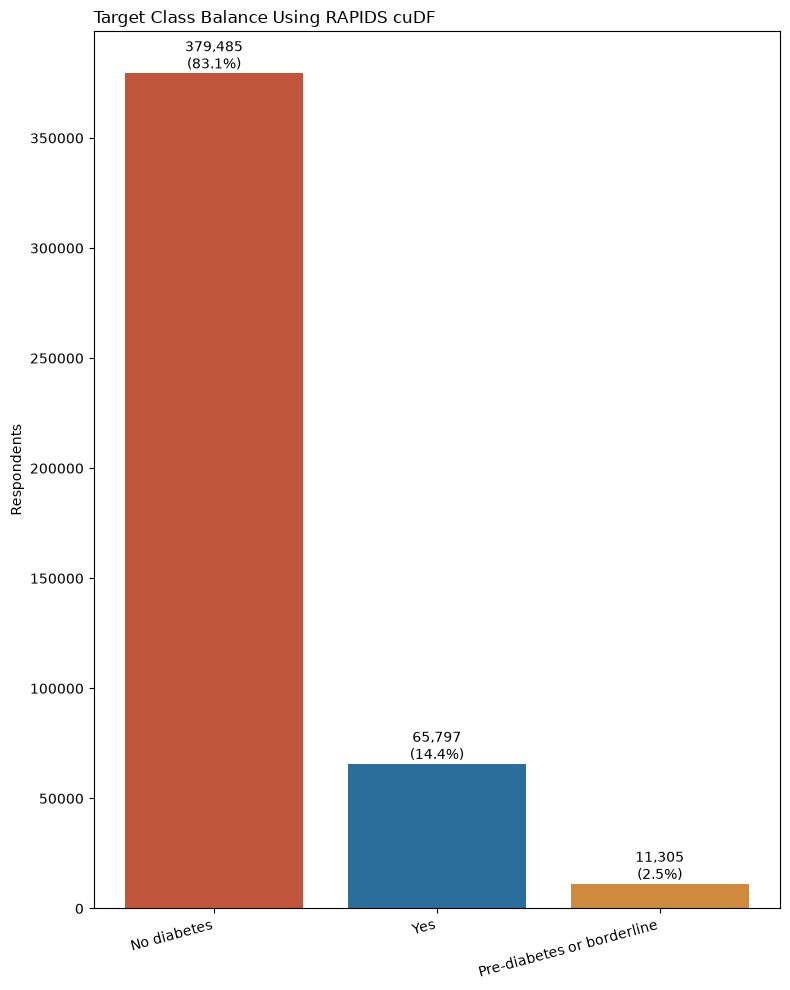

In [17]:
# Plot the target distribution calculated using cuDF.
# Matplotlib is used only for visualization after the small result is converted to pandas.

plt.figure(figsize=(8, 10))

bars = plt.bar(
    cudf_counts_pd.index,
    cudf_counts_pd.values,
    color=["#C1553B", "#2C6E9B", "#D08A3E"]
)

for bar, count, percentage in zip(
    bars,
    cudf_counts_pd.values,
    cudf_percent_pd.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.ylabel("Respondents")
plt.title(
    "Target Class Balance Using RAPIDS cuDF",
    fontsize=12,
    loc="left"
)

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Conclusion: The target variable is imbalanced. The No diabetes group is the majority class, while the Yes and Pre-diabetes or borderline groups are smaller. The pandas and cuDF results are identical because both methods use the same cleaned dataset.

This imbalance means that accuracy alone may not be sufficient for evaluating a future diabetes-prediction model. Class weights, resampling, and stratified splitting should be considered. The timing table shows whether cuDF was faster than pandas for this particular calculation.

RAPIDS EDA 2 · Numeric variables and skew

Question: What is the shape of each numeric variable, and which variables are strongly skewed?

The mean, median, minimum, maximum, and skewness are calculated using both pandas and cuDF. These results help decide whether the median is a better description of the data than the mean.

In [18]:
# Numeric summary: count, mean, median, minimum, maximum, and skewness.
# This repeats the same numeric analysis using pandas and RAPIDS cuDF.

numeric_columns = [
    "weight_pounds",
    "bmi",
    "alcohol_days_per_month",
    "alcohol_drinks_per_week",
    "age",
    "poor_health_days",
    "cigarettes_per_day",
    "pack_years",
    "binge_drinking_occasions"
]


# Calculate the numeric summary using pandas
start_time = time.perf_counter()

pandas_numeric_summary = (
    pdf[numeric_columns]
    .describe()
    .T
)

pandas_numeric_summary["skew"] = (
    pdf[numeric_columns]
    .skew()
)

pandas_numeric_summary = (
    pandas_numeric_summary
    .rename(columns={
        "count": "n",
        "50%": "median"
    })
    [["n", "mean", "median", "min", "max", "skew"]]
)

pandas_numeric_time = time.perf_counter() - start_time


# Calculate the same numeric summary using cuDF
start_time = time.perf_counter()

cudf_numeric_summary = (
    gdf[numeric_columns]
    .describe()
    .T
)

cudf_numeric_summary["skew"] = (
    gdf[numeric_columns]
    .skew()
)

cudf_numeric_summary = (
    cudf_numeric_summary
    .rename(columns={
        "count": "n",
        "50%": "median"
    })
    [["n", "mean", "median", "min", "max", "skew"]]
)

# Convert the small summary table to pandas for display
cudf_numeric_summary_pd = (
    cudf_numeric_summary
    .to_pandas()
)

rapids_numeric_time = time.perf_counter() - start_time


print("Numeric summary using pandas:")
display(pandas_numeric_summary.round(2))

print("Numeric summary using cuDF:")
display(cudf_numeric_summary_pd.round(2))


# Compare execution times
numeric_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_numeric_time,
        rapids_numeric_time
    ]
})

numeric_timing["Speedup_Ratio"] = (
    pandas_numeric_time /
    numeric_timing["Execution_Time_Seconds"]
).round(2)

print("Numeric-summary execution-time comparison:")
display(numeric_timing)

Numeric summary using pandas:


,n,mean,median,min,max,skew
weight_pounds,456587.0,182.62,178.00,50.0,776.03,1.21
bmi,456587.0,28.45,27.44,12.0,99.84,1.53
alcohol_days_per_month,456587.0,4.29,1.00,0.0,30.00,2.21
alcohol_drinks_per_week,456587.0,2.53,0.23,0.0,532.00,19.04
age,456587.0,55.09,58.00,18.0,80.00,-0.35
poor_health_days,456587.0,3.12,0.00,0.0,30.00,2.70
cigarettes_per_day,456587.0,5.03,0.00,0.0,490.00,4.37
pack_years,456587.0,6.51,0.00,0.0,1274.00,7.38
binge_drinking_occasions,456587.0,0.57,0.00,0.0,76.00,8.85


Numeric summary using cuDF:


,n,mean,median,min,max,skew
weight_pounds,456587.0,182.62,178.00,50.0,776.03,1.21
bmi,456587.0,28.45,27.44,12.0,99.84,1.53
alcohol_days_per_month,456587.0,4.29,1.00,0.0,30.00,2.21
alcohol_drinks_per_week,456587.0,2.53,0.23,0.0,532.00,19.04
age,456587.0,55.09,58.00,18.0,80.00,-0.35
poor_health_days,456587.0,3.12,0.00,0.0,30.00,2.70
cigarettes_per_day,456587.0,5.03,0.00,0.0,490.00,4.37
pack_years,456587.0,6.51,0.00,0.0,1274.00,7.38
binge_drinking_occasions,456587.0,0.57,0.00,0.0,76.00,8.85


Numeric-summary execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.628902,1.00
1,cuDF,1.426774,0.44


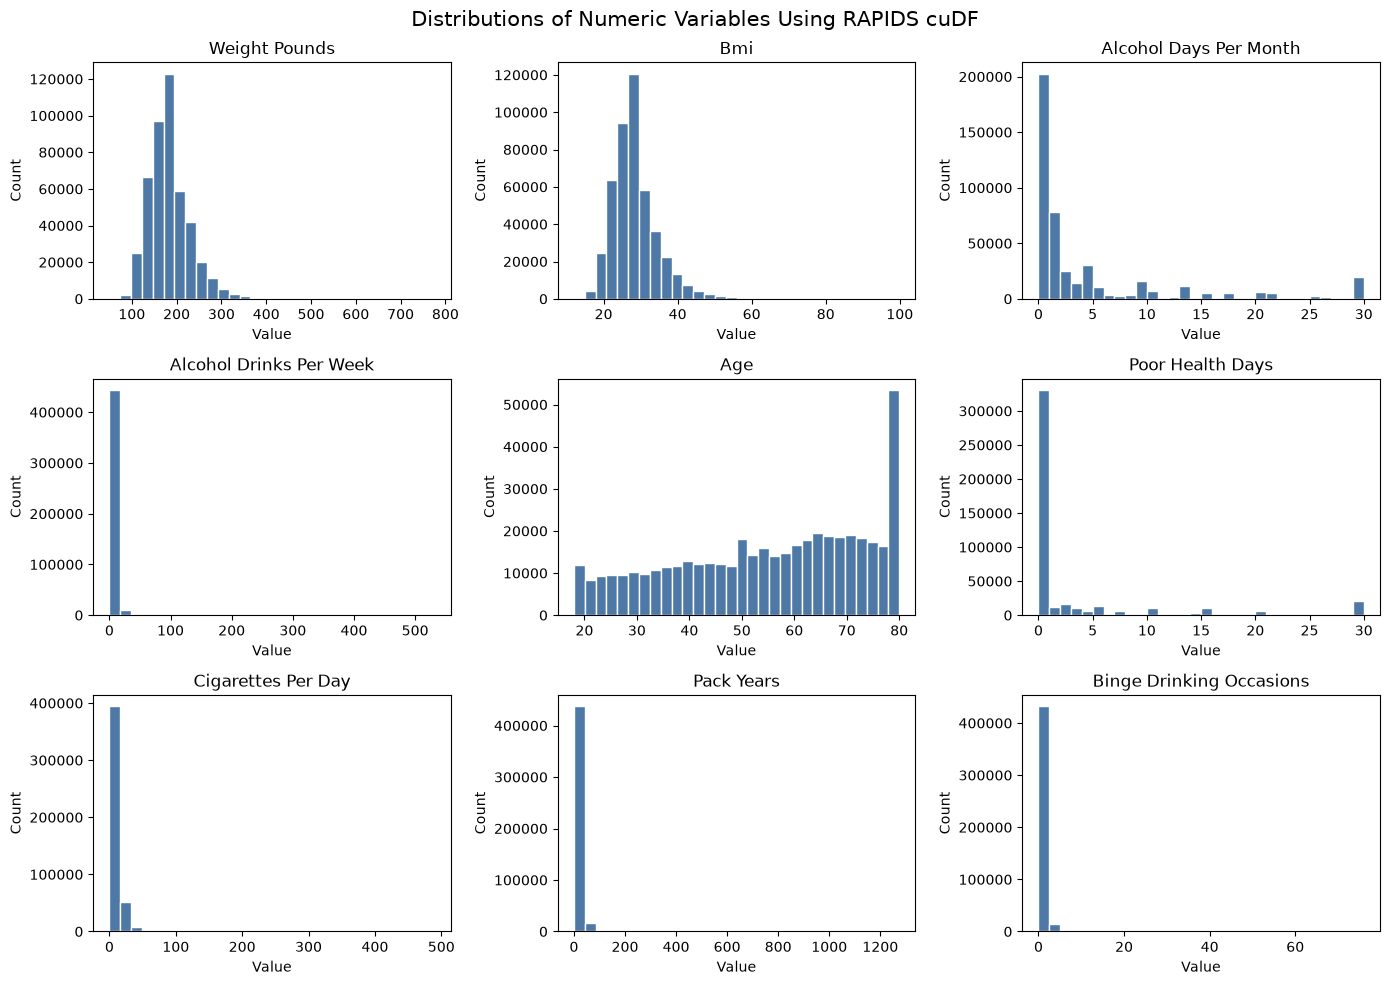

In [19]:
# Create histograms for the numeric variables.
# The data is converted to pandas only because Matplotlib is used for plotting.

numeric_plot_data = (
    gdf[numeric_columns]
    .to_pandas()
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(14, 10)
)

for ax, column in zip(axes.flat, numeric_columns):
    ax.hist(
        numeric_plot_data[column].dropna(),
        bins=30,
        color="#4E79A7",
        edgecolor="white"
    )
    
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

plt.suptitle(
    "Distributions of Numeric Variables Using RAPIDS cuDF",
    fontsize=15
)

plt.tight_layout()
plt.show()

Conclusion: Most numeric variables are right-skewed because a smaller group of respondents has unusually high values for alcohol consumption, cigarette use, or pack-years. Therefore, the median is often a more representative measure than the mean. Age is closer to a symmetric distribution than the other numeric variables.

The pandas and cuDF summaries should be very similar. The timing table shows the difference between CPU-based pandas processing and GPU-based cuDF processing for this numeric analysis.

RAPIDS EDA 3 · Lifestyle factors and diabetes prevalence

Question: Which lifestyle categories are associated with different diabetes prevalence rates?

For each category, the percentage of respondents with diabetes is calculated. The category counts are also reported so that small groups are not overinterpreted.

In [20]:
# Create a temporary binary outcome for EDA.
# This column is used only to calculate diabetes prevalence.
# It is not a final model feature.

pdf["diabetes_yes"] = (
    pdf["diabetes_status"] == "Yes"
).astype("int8")

gdf["diabetes_yes"] = (
    gdf["diabetes_status"] == "Yes"
).astype("int8")


lifestyle_columns = [
    "physical_activity",
    "leisure_physical_activity",
    "bmi_category",
    "smoked_100_cigarettes",
    "smokeless_tobacco_use",
    "e_cigarette_use"
]


# Calculate prevalence using pandas
start_time = time.perf_counter()

pandas_lifestyle_results = {}

for column in lifestyle_columns:
    table = (
        pdf.groupby(column)["diabetes_yes"]
        .agg(["mean", "count"])
        .reset_index()
    )
    
    table["Diabetes_Percent"] = (
        table["mean"] * 100
    ).round(2)
    
    pandas_lifestyle_results[column] = table

pandas_lifestyle_time = time.perf_counter() - start_time


# Calculate the same prevalence using cuDF
start_time = time.perf_counter()

cudf_lifestyle_results = {}

for column in lifestyle_columns:
    table = (
        gdf.groupby(column)["diabetes_yes"]
        .agg(["mean", "count"])
        .reset_index()
    )
    
    table["Diabetes_Percent"] = (
        table["mean"] * 100
    ).round(2)
    
    cudf_lifestyle_results[column] = table


# Convert the small grouped results to pandas for display and plotting
cudf_lifestyle_results_pd = {
    column: table.to_pandas()
    for column, table in cudf_lifestyle_results.items()
}

rapids_lifestyle_time = time.perf_counter() - start_time


# Print the lowest and highest prevalence for each lifestyle variable
print("Lifestyle prevalence results using cuDF:")

for column, table in cudf_lifestyle_results_pd.items():
    ordered_table = table.sort_values("Diabetes_Percent")
    
    lowest = ordered_table.iloc[0]
    highest = ordered_table.iloc[-1]
    
    print(
        f"{column}: "
        f"lowest = {lowest[column]} "
        f"{lowest['Diabetes_Percent']:.1f}% "
        f"(n={int(lowest['count']):,}) | "
        f"highest = {highest[column]} "
        f"{highest['Diabetes_Percent']:.1f}% "
        f"(n={int(highest['count']):,})"
    )


# Compare execution times
lifestyle_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_lifestyle_time,
        rapids_lifestyle_time
    ]
})

lifestyle_timing["Speedup_Ratio"] = (
    pandas_lifestyle_time /
    lifestyle_timing["Execution_Time_Seconds"]
).round(2)

print("\nLifestyle-analysis execution-time comparison:")
display(lifestyle_timing)

Lifestyle prevalence results using cuDF:
physical_activity: lowest = Yes 11.7% (n=349,394) | highest = No 23.4% (n=105,950)
leisure_physical_activity: lowest = Yes 11.7% (n=349,394) | highest = No 23.4% (n=105,950)
bmi_category: lowest = Underweight 6.0% (n=7,358) | highest = Obese 22.5% (n=139,348)
smoked_100_cigarettes: lowest = No 12.7% (n=258,454) | highest = Yes 17.2% (n=166,875)
smokeless_tobacco_use: lowest = Some days 11.3% (n=5,268) | highest = Every day 15.9% (n=7,351)
e_cigarette_use: lowest = Some days 8.0% (n=11,351) | highest = Never used 15.4% (n=342,584)

Lifestyle-analysis execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.616846,1.0
1,cuDF,0.384859,1.6


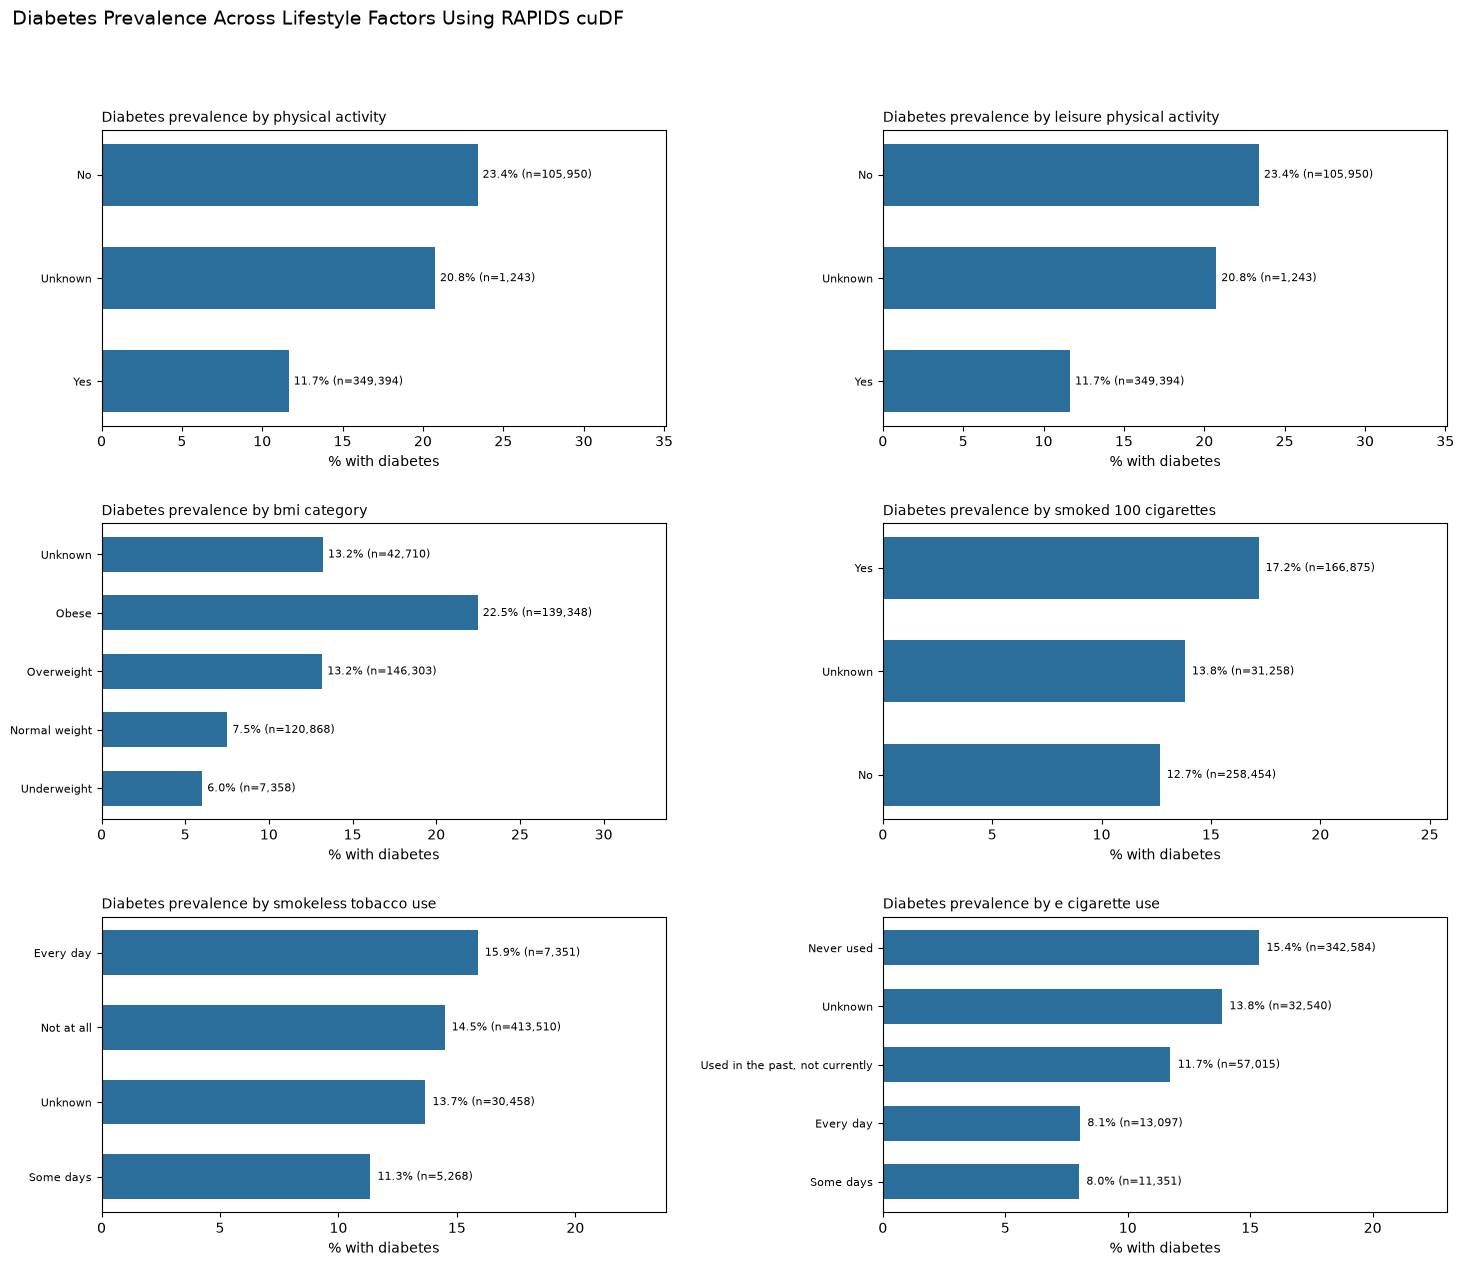

In [21]:
# Plot diabetes prevalence across lifestyle categories.
# The grouped cuDF results are converted to pandas only for Matplotlib.

plot_order = {
    "physical_activity": None,
    "leisure_physical_activity": None,
    "bmi_category": [
        "Underweight",
        "Normal weight",
        "Overweight",
        "Obese",
        "Unknown"
    ],
    "smoked_100_cigarettes": None,
    "smokeless_tobacco_use": None,
    "e_cigarette_use": None
}

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 13)
)

for ax, column in zip(axes.flat, lifestyle_columns):
    plot_table = cudf_lifestyle_results_pd[column].copy()
    
    category_order = plot_order[column]
    
    if category_order is not None:
        plot_table["_order"] = pd.Categorical(
            plot_table[column],
            categories=category_order,
            ordered=True
        )
        plot_table = plot_table.sort_values("_order")
    else:
        plot_table = plot_table.sort_values("Diabetes_Percent")
    
    y_positions = range(len(plot_table))
    
    ax.barh(
        list(y_positions),
        plot_table["Diabetes_Percent"],
        color="#2C6E9B",
        height=0.6
    )
    
    for position, percentage, count in zip(
        y_positions,
        plot_table["Diabetes_Percent"],
        plot_table["count"]
    ):
        ax.text(
            percentage + 0.3,
            position,
            f"{percentage:.1f}% (n={int(count):,})",
            va="center",
            fontsize=8
        )
    
    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(
        plot_table[column],
        fontsize=8
    )
    
    ax.set_xlabel("% with diabetes")
    ax.set_title(
        f"Diabetes prevalence by {column.replace('_', ' ')}",
        fontsize=10,
        loc="left"
    )
    
    ax.set_xlim(
        0,
        plot_table["Diabetes_Percent"].max() * 1.5
    )

fig.suptitle(
    "Diabetes Prevalence Across Lifestyle Factors Using RAPIDS cuDF",
    fontsize=14,
    x=0.02,
    ha="left"
)

plt.tight_layout(
    pad=2.0,
    h_pad=2.5,
    w_pad=2.5,
    rect=[0, 0, 1, 0.96]
)

plt.show()

Conclusion: Inactivity is associated with a higher diabetes prevalence than physical activity. Obesity also shows a higher diabetes prevalence than the lower BMI categories. The tobacco categories show smaller differences, suggesting a weaker relationship in this dataset. The smokeless-tobacco and e-cigarette groups are relatively small, so their percentages should be interpreted carefully.

Physical activity and BMI category are useful candidate features for the prediction model. The category counts should be considered before interpreting small groups.

RAPIDS EDA 4 · Demographic and socioeconomic factors

Question: Which demographic, income, marital-status, and alcohol-use categories have different diabetes prevalence rates?

The percentage of respondents with diabetes is calculated within each category. The group counts are also included so that small groups are not overinterpreted.

In [22]:
# Calculate diabetes prevalence across demographic and socioeconomic categories.
# This repeats the same analysis using pandas and RAPIDS cuDF.

demographic_columns = [
    "education_level",
    "income_group",
    "detailed_income_level",
    "marital_status",
    "alcohol_use_past_30_days",
    "heavy_alcohol_use"
]


# Calculate results using pandas
start_time = time.perf_counter()

pandas_demographic_results = {}

for column in demographic_columns:
    table = (
        pdf.groupby(column)["diabetes_yes"]
        .agg(["mean", "count"])
        .reset_index()
    )
    
    table["Diabetes_Percent"] = (
        table["mean"] * 100
    ).round(2)
    
    pandas_demographic_results[column] = table

pandas_demographic_time = time.perf_counter() - start_time


# Calculate the same results using cuDF
start_time = time.perf_counter()

cudf_demographic_results = {}

for column in demographic_columns:
    table = (
        gdf.groupby(column)["diabetes_yes"]
        .agg(["mean", "count"])
        .reset_index()
    )
    
    table["Diabetes_Percent"] = (
        table["mean"] * 100
    ).round(2)
    
    cudf_demographic_results[column] = table


# Convert small summary tables to pandas for display
cudf_demographic_results_pd = {
    column: table.to_pandas()
    for column, table in cudf_demographic_results.items()
}

rapids_demographic_time = time.perf_counter() - start_time


# Print the lowest and highest prevalence for each variable
print("Demographic and socioeconomic prevalence results using cuDF:")

for column, table in cudf_demographic_results_pd.items():
    ordered_table = table.sort_values("Diabetes_Percent")
    
    lowest = ordered_table.iloc[0]
    highest = ordered_table.iloc[-1]
    
    print(
        f"{column}: "
        f"lowest = {lowest[column]} "
        f"{lowest['Diabetes_Percent']:.1f}% "
        f"(n={int(lowest['count']):,}) | "
        f"highest = {highest[column]} "
        f"{highest['Diabetes_Percent']:.1f}% "
        f"(n={int(highest['count']):,})"
    )


# Compare execution times
demographic_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_demographic_time,
        rapids_demographic_time
    ]
})

demographic_timing["Speedup_Ratio"] = (
    pandas_demographic_time /
    demographic_timing["Execution_Time_Seconds"]
).round(2)

print("\nDemographic-analysis execution-time comparison:")
display(demographic_timing)

Demographic and socioeconomic prevalence results using cuDF:
education_level: lowest = College graduate 11.1% (n=191,279) | highest = Never attended school or kindergarten 26.6% (n=718)
income_group: lowest = $200,000 or more 6.8% (n=29,673) | highest = $15,000 to less than $25,000 22.4% (n=33,382)
detailed_income_level: lowest = $200,000 or more 6.8% (n=29,673) | highest = $10,000 to less than $15,000 24.6% (n=10,506)
marital_status: lowest = Unmarried couple 7.4% (n=21,698) | highest = Widowed 22.9% (n=49,033)
alcohol_use_past_30_days: lowest = Yes 9.8% (n=210,335) | highest = No 19.4% (n=202,729)
heavy_alcohol_use: lowest = Yes 7.0% (n=24,118) | highest = No 15.0% (n=386,040)

Demographic-analysis execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.450022,1.0
1,cuDF,0.214745,2.1


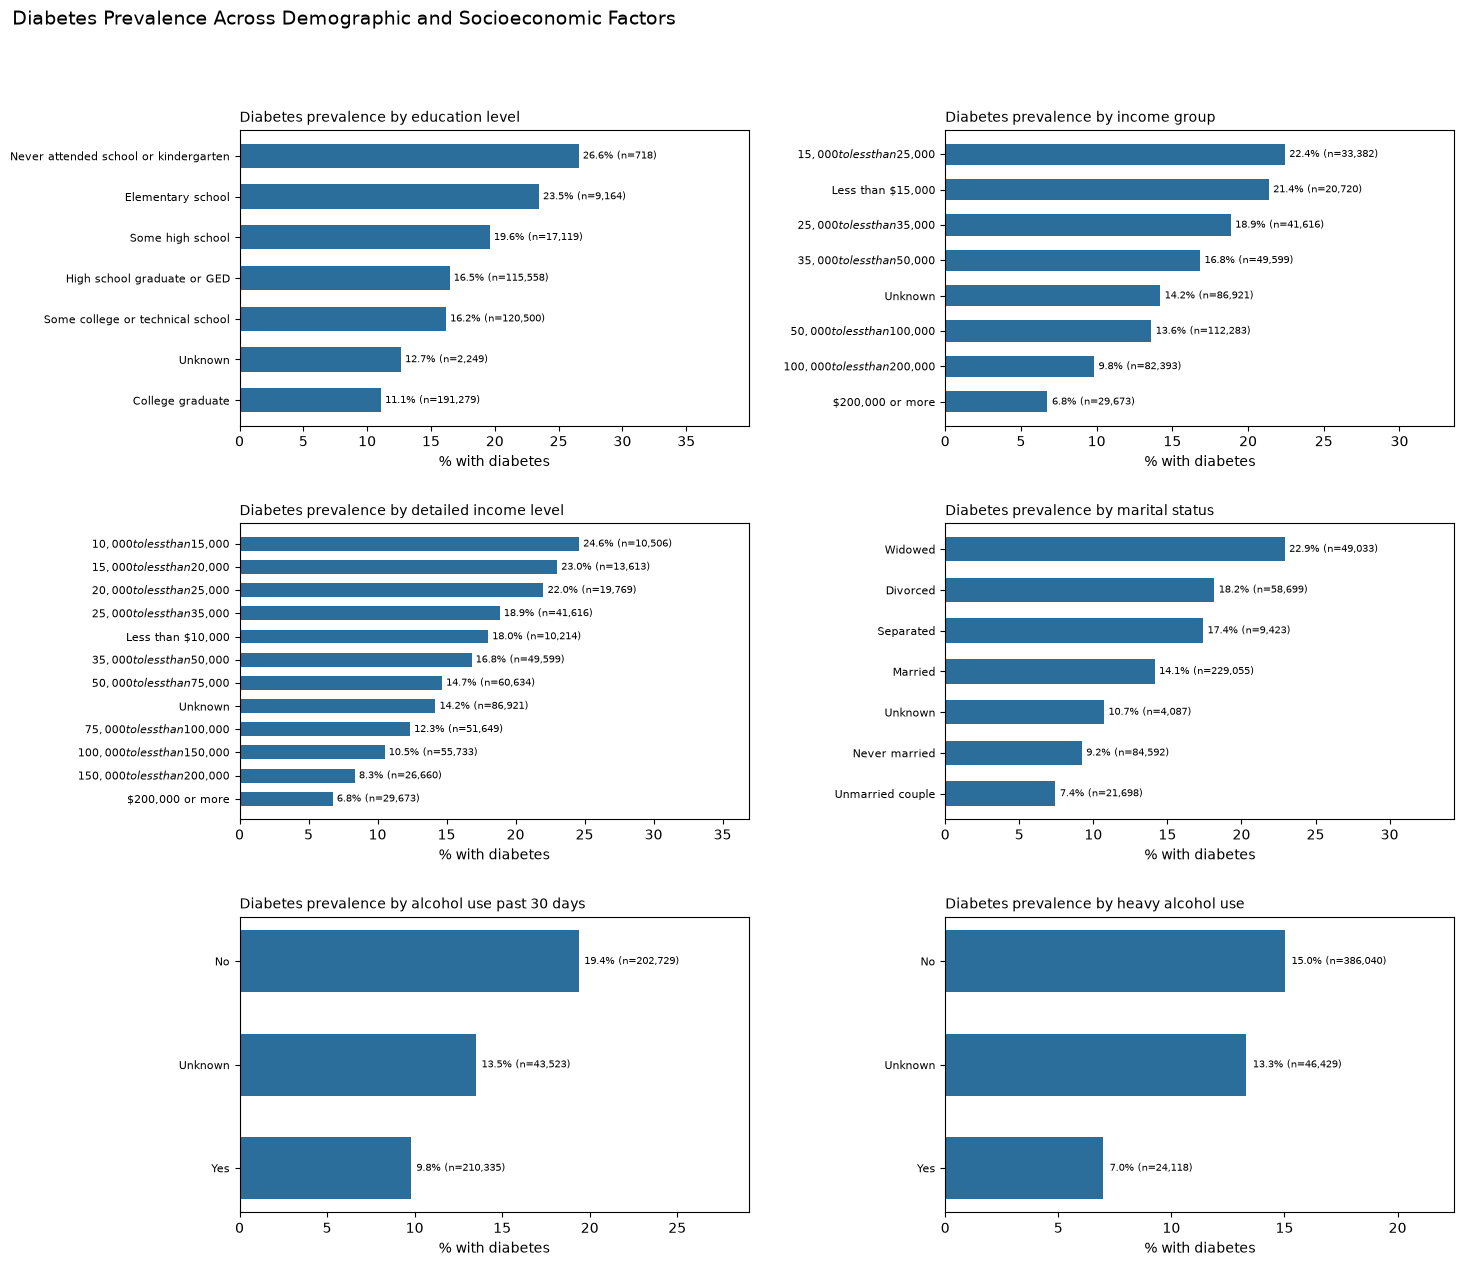

In [23]:
# Plot diabetes prevalence across demographic and socioeconomic categories.
# The cuDF results are converted to pandas only for Matplotlib plotting.

fig, axes = plt.subplots(
    3,
    2,
    figsize=(15, 13)
)

for ax, column in zip(axes.flat, demographic_columns):
    plot_table = (
        cudf_demographic_results_pd[column]
        .sort_values("Diabetes_Percent")
    )
    
    y_positions = range(len(plot_table))
    
    ax.barh(
        list(y_positions),
        plot_table["Diabetes_Percent"],
        color="#2C6E9B",
        height=0.6
    )
    
    for position, percentage, count in zip(
        y_positions,
        plot_table["Diabetes_Percent"],
        plot_table["count"]
    ):
        ax.text(
            percentage + 0.3,
            position,
            f"{percentage:.1f}% (n={int(count):,})",
            va="center",
            fontsize=7.5
        )
    
    ax.set_yticks(list(y_positions))
    ax.set_yticklabels(
        plot_table[column].astype(str),
        fontsize=8
    )
    
    ax.set_xlabel("% with diabetes")
    ax.set_title(
        f"Diabetes prevalence by {column.replace('_', ' ')}",
        fontsize=10,
        loc="left"
    )
    
    ax.set_xlim(
        0,
        plot_table["Diabetes_Percent"].max() * 1.5
    )

fig.suptitle(
    "Diabetes Prevalence Across Demographic and Socioeconomic Factors",
    fontsize=14,
    x=0.02,
    ha="left"
)

plt.tight_layout(
    pad=2.0,
    h_pad=2.5,
    w_pad=2.5,
    rect=[0, 0, 1, 0.96]
)

plt.show()

Conclusion: Diabetes prevalence generally decreases as education and income increase. Older or widowed respondents show higher prevalence than younger or unmarried groups. The alcohol-use groups also show differences, although these results describe associations and do not prove that alcohol use causes or prevents diabetes.

Education, income, marital status, and age-related variables may help the prediction model identify differences between respondents. Category counts should be checked before interpreting very small groups.

RAPIDS EDA 5 · Age group and gender

Question: How are diabetes and pre-diabetes cases distributed across age groups and gender?

This analysis counts diabetes and pre-diabetes respondents within each age and gender group. The results may help identify whether age and gender should be included as prediction features.

In [26]:
# Count diabetes and pre-diabetes cases by age group and gender.
# This repeats the same analysis using pandas and RAPIDS cuDF.

import numpy as np

age_order = [
    "18-24",
    "25-29",
    "30-34",
    "35-39",
    "40-44",
    "45-49",
    "50-54",
    "55-59",
    "60-64",
    "65-69",
    "70-74",
    "75-79",
    "80+"
]

gender_order = [
    "Male",
    "Female"
]

diabetes_status_order = [
    "Yes",
    "Pre-diabetes or borderline"
]


# Filter to diabetes and pre-diabetes respondents
pandas_age_gender_data = pdf[
    pdf["diabetes_status"].isin(diabetes_status_order)
]

gdf_age_gender_data = gdf[
    gdf["diabetes_status"].isin(diabetes_status_order)
]


# Calculate counts using pandas
start_time = time.perf_counter()

pandas_age_gender_counts = (
    pandas_age_gender_data
    .groupby(
        ["age_group", "gender", "diabetes_status"]
    )
    .size()
    .reset_index(name="Respondent_Count")
)

pandas_age_gender_time = time.perf_counter() - start_time


# Calculate the same counts using cuDF
start_time = time.perf_counter()

cudf_age_gender_counts = (
    gdf_age_gender_data
    .groupby(
        ["age_group", "gender", "diabetes_status"]
    )
    .size()
    .reset_index(name="Respondent_Count")
)

# Convert the small grouped result to pandas for display and plotting
cudf_age_gender_counts_pd = (
    cudf_age_gender_counts
    .to_pandas()
)

rapids_age_gender_time = time.perf_counter() - start_time


print("Total diabetes and pre-diabetes respondents using pandas:",
      pandas_age_gender_counts["Respondent_Count"].sum())

print("Total diabetes and pre-diabetes respondents using cuDF:",
      cudf_age_gender_counts_pd["Respondent_Count"].sum())

print("\nSample of the cuDF result:")
display(cudf_age_gender_counts_pd.head(10))


# Compare execution times
age_gender_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_age_gender_time,
        rapids_age_gender_time
    ]
})

age_gender_timing["Speedup_Ratio"] = (
    pandas_age_gender_time /
    age_gender_timing["Execution_Time_Seconds"]
).round(2)

print("Age-and-gender execution-time comparison:")
display(age_gender_timing)

Total diabetes and pre-diabetes respondents using pandas: 77102
Total diabetes and pre-diabetes respondents using cuDF: 77102

Sample of the cuDF result:


,age_group,gender,diabetes_status,Respondent_Count
0,40-44,Male,Pre-diabetes or borderline,262
1,50-54,Female,Pre-diabetes or borderline,541
2,70-74,Female,Pre-diabetes or borderline,773
3,70-74,Male,Pre-diabetes or borderline,690
4,40-44,Female,Yes,1092
5,55-59,Female,Yes,3084
6,55-59,Male,Yes,3047
7,30-34,Female,Pre-diabetes or borderline,213
8,65-69,Male,Pre-diabetes or borderline,656
9,80+,Male,Pre-diabetes or borderline,467


Age-and-gender execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.015440,1.00
1,cuDF,0.024938,0.62


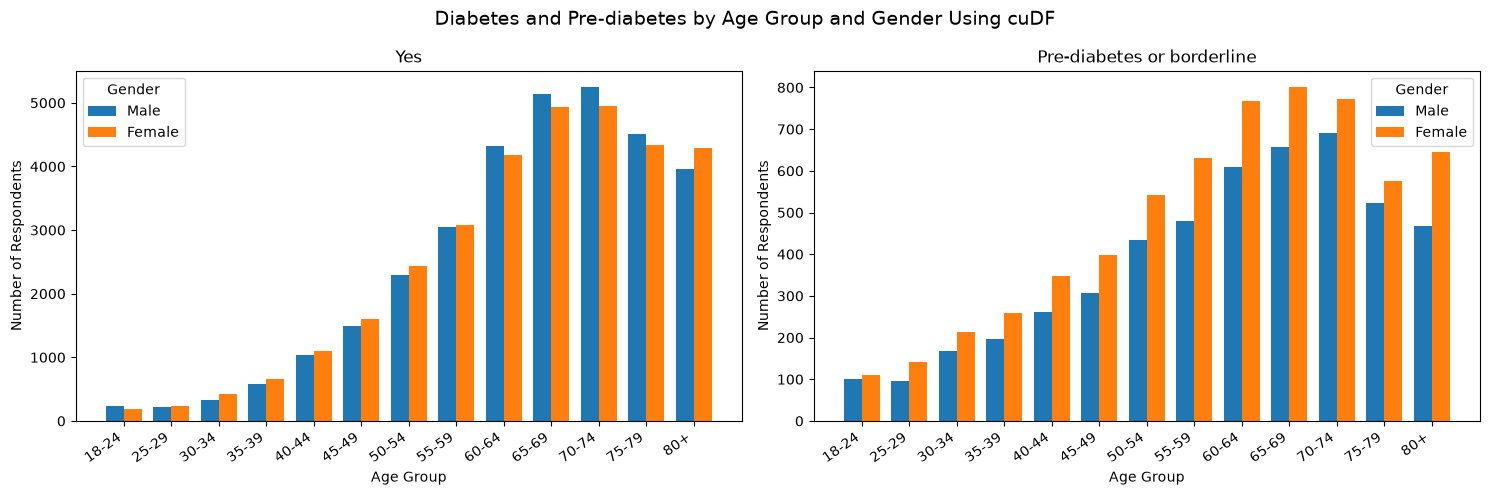

In [27]:
# Plot diabetes and pre-diabetes counts by age group and gender.
# The grouped cuDF result is converted to pandas only for Matplotlib.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

x_positions = np.arange(len(age_order))
bar_width = 0.38

for ax, diabetes_status in zip(
    axes,
    diabetes_status_order
):
    status_data = cudf_age_gender_counts_pd[
        cudf_age_gender_counts_pd["diabetes_status"]
        == diabetes_status
    ]
    
    for index, gender in enumerate(gender_order):
        gender_counts = (
            status_data[
                status_data["gender"] == gender
            ]
            .set_index("age_group")["Respondent_Count"]
            .reindex(age_order)
            .fillna(0)
        )
        
        ax.bar(
            x_positions + (index - 0.5) * bar_width,
            gender_counts.values,
            width=bar_width,
            label=gender
        )
    
    ax.set_title(diabetes_status)
    ax.set_xlabel("Age Group")
    ax.set_ylabel("Number of Respondents")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        age_order,
        rotation=35,
        ha="right"
    )
    ax.legend(title="Gender")

fig.suptitle(
    "Diabetes and Pre-diabetes by Age Group and Gender Using cuDF",
    fontsize=14
)

plt.tight_layout()
plt.show()

Conclusion: Diabetes and pre-diabetes cases are concentrated more heavily in the older age groups. The general pattern is similar for males and females, although the number of respondents differs between genders in some age groups.

Age group is likely to be an important predictor because the distribution changes substantially across age categories. Gender may also provide additional information, although the relationship appears weaker than the age pattern.

RAPIDS EDA 6 · General health and physical activity

Question: Do general health and physical activity separate diabetes status?

Both respondent counts and within-group percentages are calculated. Percentages provide a fairer comparison because the health and activity groups do not all contain the same number of respondents.

In [28]:
# Analyze diabetes status by general health and physical activity.
# This repeats the same analysis using pandas and RAPIDS cuDF.

health_order = [
    "Excellent",
    "Very good",
    "Good",
    "Fair",
    "Poor"
]

activity_order = [
    "Yes",
    "No"
]

diabetes_order = [
    "Yes",
    "Pre-diabetes or borderline"
]


# Keep valid general-health and physical-activity categories
pandas_health_data = pdf[
    pdf["physical_activity"].isin(activity_order) &
    pdf["general_health"].isin(health_order)
]

gdf_health_data = gdf[
    gdf["physical_activity"].isin(activity_order) &
    gdf["general_health"].isin(health_order)
]


# Calculate counts and percentages using pandas
start_time = time.perf_counter()

pandas_health_counts = (
    pandas_health_data
    .groupby(
        [
            "physical_activity",
            "general_health",
            "diabetes_status"
        ]
    )
    .size()
    .reset_index(name="Count")
)

pandas_health_totals = (
    pandas_health_counts
    .groupby(
        [
            "physical_activity",
            "general_health"
        ]
    )["Count"]
    .sum()
    .reset_index(name="Total_Count")
)

pandas_health_summary = pandas_health_counts.merge(
    pandas_health_totals,
    on=["physical_activity", "general_health"]
)

pandas_health_summary["Percentage"] = (
    pandas_health_summary["Count"] /
    pandas_health_summary["Total_Count"] *
    100
).round(2)

pandas_health_time = time.perf_counter() - start_time


# Calculate the same counts and percentages using cuDF
start_time = time.perf_counter()

cudf_health_counts = (
    gdf_health_data
    .groupby(
        [
            "physical_activity",
            "general_health",
            "diabetes_status"
        ]
    )
    .size()
    .reset_index(name="Count")
)

cudf_health_totals = (
    cudf_health_counts
    .groupby(
        [
            "physical_activity",
            "general_health"
        ]
    )["Count"]
    .sum()
    .reset_index(name="Total_Count")
)

cudf_health_summary = cudf_health_counts.merge(
    cudf_health_totals,
    on=["physical_activity", "general_health"]
)

cudf_health_summary["Percentage"] = (
    cudf_health_summary["Count"] /
    cudf_health_summary["Total_Count"] *
    100
).round(2)

# Convert the small summary table to pandas for display and plotting
cudf_health_summary_pd = (
    cudf_health_summary
    .to_pandas()
)

rapids_health_time = time.perf_counter() - start_time


print("Health and activity summary using cuDF:")
display(cudf_health_summary_pd.head(12))


# Compare execution times
health_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_health_time,
        rapids_health_time
    ]
})

health_timing["Speedup_Ratio"] = (
    pandas_health_time /
    health_timing["Execution_Time_Seconds"]
).round(2)

print("Health-and-activity execution-time comparison:")
display(health_timing)

Health and activity summary using cuDF:


,physical_activity,general_health,diabetes_status,Count,Total_Count,Percentage
0,No,Good,No diabetes,29421,38920,75.59
1,No,Fair,Pre-diabetes or borderline,1137,26963,4.22
2,Yes,Excellent,No diabetes,54599,56727,96.25
3,Yes,Fair,No diabetes,28506,40427,70.51
4,Yes,Poor,No diabetes,5870,9167,64.03
5,Yes,Good,No diabetes,96304,116480,82.68
6,No,Good,Pre-diabetes or borderline,1211,38920,3.11
7,No,Very good,Yes,2431,19559,12.43
8,Yes,Very good,No diabetes,114908,125813,91.33
9,No,Excellent,Pre-diabetes or borderline,123,7288,1.69


Health-and-activity execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.164886,1.00
1,cuDF,0.935140,0.18


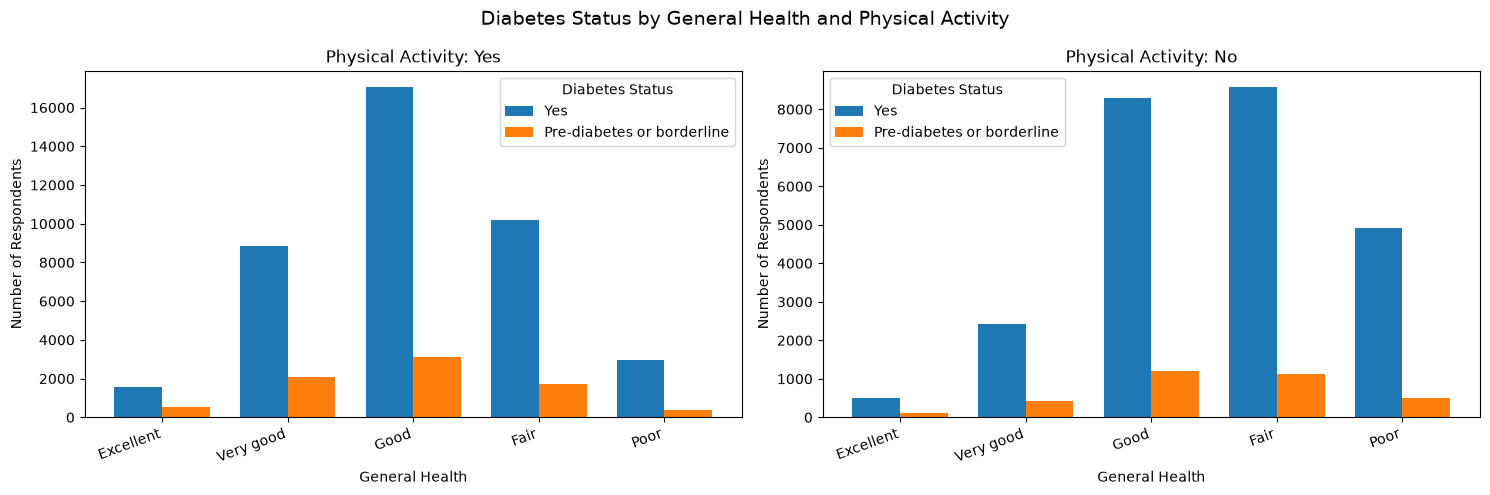

In [29]:
# Plot diabetes and pre-diabetes respondent counts.
# The cuDF results are converted to pandas only for Matplotlib.

def plot_health_chart(
    ax,
    activity_value,
    value_column,
    y_label,
    chart_title
):
    plot_data = cudf_health_summary_pd[
        (
            cudf_health_summary_pd["physical_activity"]
            == activity_value
        ) &
        (
            cudf_health_summary_pd["diabetes_status"]
            .isin(diabetes_order)
        )
    ]
    
    x_positions = np.arange(len(health_order))
    bar_width = 0.38
    
    for index, diabetes_status in enumerate(diabetes_order):
        status_data = (
            plot_data[
                plot_data["diabetes_status"]
                == diabetes_status
            ]
            .set_index("general_health")
            [value_column]
            .reindex(health_order)
            .fillna(0)
        )
        
        bars = ax.bar(
            x_positions + (index - 0.5) * bar_width,
            status_data.values,
            width=bar_width,
            label=diabetes_status
        )
        
        if value_column == "Percentage":
            for bar in bars:
                if bar.get_height() > 0:
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 1,
                        f"{bar.get_height():.1f}%",
                        ha="center",
                        fontsize=8
                    )
    
    ax.set_title(chart_title)
    ax.set_xlabel("General Health")
    ax.set_ylabel(y_label)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        health_order,
        rotation=20,
        ha="right"
    )
    ax.legend(title="Diabetes Status")


fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

for ax, activity_value in zip(axes, activity_order):
    plot_health_chart(
        ax=ax,
        activity_value=activity_value,
        value_column="Count",
        y_label="Number of Respondents",
        chart_title=f"Physical Activity: {activity_value}"
    )

fig.suptitle(
    "Diabetes Status by General Health and Physical Activity",
    fontsize=14
)

plt.tight_layout()
plt.show()

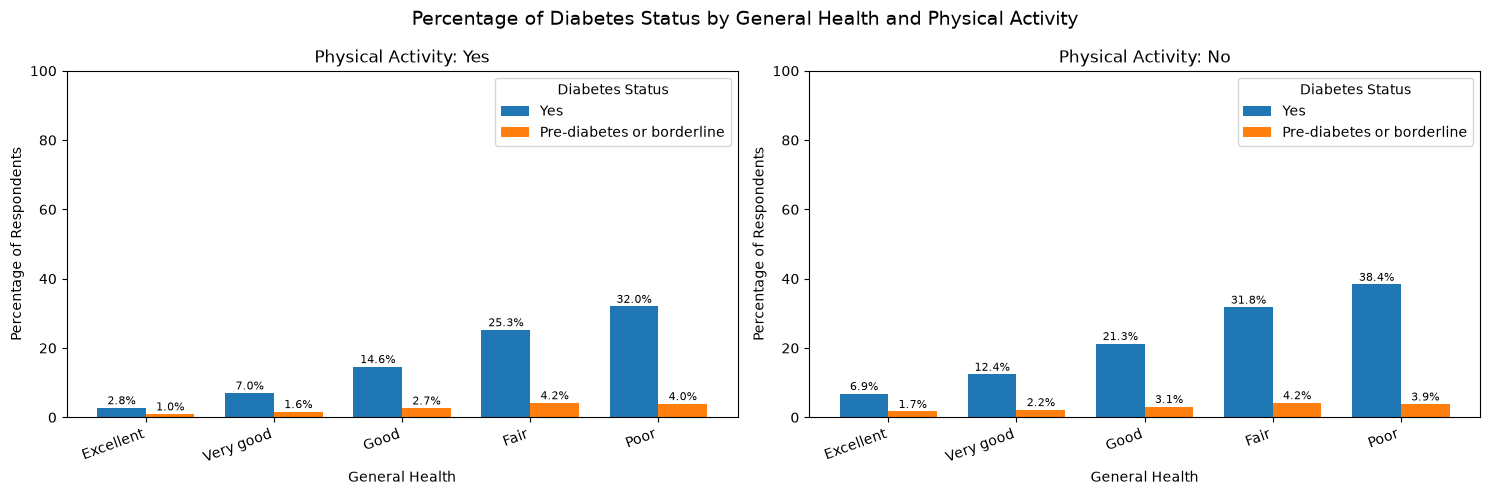

In [30]:
# Plot diabetes and pre-diabetes percentages within each
# general-health and physical-activity group.

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

for ax, activity_value in zip(axes, activity_order):
    plot_health_chart(
        ax=ax,
        activity_value=activity_value,
        value_column="Percentage",
        y_label="Percentage of Respondents",
        chart_title=f"Physical Activity: {activity_value}"
    )
    
    ax.set_ylim(0, 100)

fig.suptitle(
    "Percentage of Diabetes Status by General Health and Physical Activity",
    fontsize=14
)

plt.tight_layout()
plt.show()

Conclusion: Diabetes prevalence increases as self-rated health changes from excellent to poor. Within the same health category, respondents who are not physically active generally show a higher diabetes percentage than active respondents.

The percentage graph is more useful than the count graph for comparing groups because it accounts for different group sizes. General health and physical activity should be retained as potential model features, and their interaction may also be useful.

RAPIDS EDA 7 · Smoking status and diabetes

Question: Does diabetes status vary across smoking-status categories?

The percentage of each diabetes-status group is calculated within each smoking category. The size of each smoking group is also reported before comparing the percentages.

In [31]:
# Calculate diabetes-status percentages within each smoking-status group.
# This repeats the same analysis using pandas and RAPIDS cuDF.

smoking_order = [
    "Current smoker - every day",
    "Current smoker - some days",
    "Former smoker",
    "Never smoker"
]

diabetes_status_order = [
    "No diabetes",
    "Yes",
    "Pre-diabetes or borderline"
]


# Keep only the defined smoking categories
pandas_smoking_data = pdf[
    pdf["smoking_status"].isin(smoking_order)
]

gdf_smoking_data = gdf[
    gdf["smoking_status"].isin(smoking_order)
]


# Calculate percentages using pandas
start_time = time.perf_counter()

pandas_smoking_counts = (
    pandas_smoking_data
    .groupby(
        ["smoking_status", "diabetes_status"]
    )
    .size()
    .reset_index(name="Count")
)

pandas_smoking_totals = (
    pandas_smoking_counts
    .groupby("smoking_status")["Count"]
    .sum()
    .reset_index(name="Total_Count")
)

pandas_smoking_summary = pandas_smoking_counts.merge(
    pandas_smoking_totals,
    on="smoking_status"
)

pandas_smoking_summary["Percentage"] = (
    pandas_smoking_summary["Count"] /
    pandas_smoking_summary["Total_Count"] *
    100
).round(2)

pandas_smoking_time = time.perf_counter() - start_time


# Calculate the same percentages using cuDF
start_time = time.perf_counter()

cudf_smoking_counts = (
    gdf_smoking_data
    .groupby(
        ["smoking_status", "diabetes_status"]
    )
    .size()
    .reset_index(name="Count")
)

cudf_smoking_totals = (
    cudf_smoking_counts
    .groupby("smoking_status")["Count"]
    .sum()
    .reset_index(name="Total_Count")
)

cudf_smoking_summary = cudf_smoking_counts.merge(
    cudf_smoking_totals,
    on="smoking_status"
)

cudf_smoking_summary["Percentage"] = (
    cudf_smoking_summary["Count"] /
    cudf_smoking_summary["Total_Count"] *
    100
).round(2)

# Convert the small grouped result to pandas for display and plotting
cudf_smoking_summary_pd = (
    cudf_smoking_summary
    .to_pandas()
)

rapids_smoking_time = time.perf_counter() - start_time


# Show the number of respondents in each smoking group
print("Respondents in each smoking category:")
display(
    gdf_smoking_data["smoking_status"]
    .value_counts()
    .to_pandas()
    .reindex(smoking_order)
    .to_frame("Respondent_Count")
)


print("Smoking-status percentage table using cuDF:")
display(
    cudf_smoking_summary_pd
    .sort_values(
        ["smoking_status", "diabetes_status"]
    )
)


# Compare execution times
smoking_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_smoking_time,
        rapids_smoking_time
    ]
})

smoking_timing["Speedup_Ratio"] = (
    pandas_smoking_time /
    smoking_timing["Execution_Time_Seconds"]
).round(2)

print("Smoking-analysis execution-time comparison:")
display(smoking_timing)

Respondents in each smoking category:


,Respondent_Count
smoking_status,
Current smoker - every day,33019
Current smoker - some days,13925
Former smoker,119385
Never smoker,258454


Smoking-status percentage table using cuDF:


,smoking_status,diabetes_status,Count,Total_Count,Percentage
0,Current smoker - every day,No diabetes,26725,33019,80.94
9,Current smoker - every day,Pre-diabetes or borderline,1012,33019,3.06
5,Current smoker - every day,Yes,5282,33019,16.00
2,Current smoker - some days,No diabetes,11741,13925,84.32
4,Current smoker - some days,Pre-diabetes or borderline,380,13925,2.73
6,Current smoker - some days,Yes,1804,13925,12.96
8,Former smoker,No diabetes,94570,119385,79.21
3,Former smoker,Pre-diabetes or borderline,3300,119385,2.76
7,Former smoker,Yes,21515,119385,18.02
1,Never smoker,No diabetes,219722,258454,85.01


Smoking-analysis execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.052319,1.00
1,cuDF,0.046519,1.12


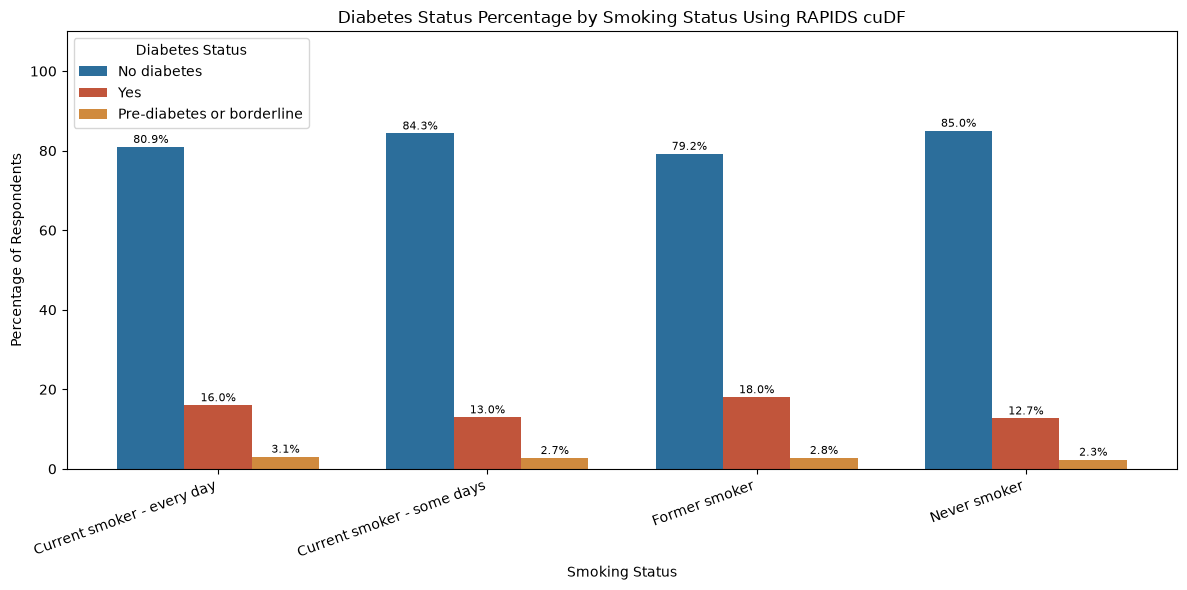

In [32]:
# Plot the percentage of each diabetes-status group within smoking categories.
# The cuDF result is converted to pandas only for Matplotlib.

plot_data = cudf_smoking_summary_pd.copy()

x_positions = np.arange(len(smoking_order))
bar_width = 0.25

colors = {
    "No diabetes": "#2C6E9B",
    "Yes": "#C1553B",
    "Pre-diabetes or borderline": "#D08A3E"
}

plt.figure(figsize=(12, 6))

for index, diabetes_status in enumerate(diabetes_status_order):
    status_values = (
        plot_data[
            plot_data["diabetes_status"]
            == diabetes_status
        ]
        .set_index("smoking_status")["Percentage"]
        .reindex(smoking_order)
        .fillna(0)
    )
    
    bars = plt.bar(
        x_positions + (index - 1) * bar_width,
        status_values.values,
        width=bar_width,
        label=diabetes_status,
        color=colors[diabetes_status]
    )
    
    for bar in bars:
        if bar.get_height() > 0:
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1,
                f"{bar.get_height():.1f}%",
                ha="center",
                fontsize=8
            )

plt.title(
    "Diabetes Status Percentage by Smoking Status Using RAPIDS cuDF"
)

plt.xlabel("Smoking Status")
plt.ylabel("Percentage of Respondents")
plt.xticks(
    x_positions,
    smoking_order,
    rotation=20,
    ha="right"
)

plt.ylim(0, 110)
plt.legend(title="Diabetes Status")
plt.tight_layout()
plt.show()

Conclusion: The percentages across smoking categories are relatively similar compared with the stronger patterns observed for age, BMI, physical activity, and general health. This suggests that smoking status has a weaker individual relationship with diabetes in this dataset.

Smoking status can still be retained as a possible model feature, but it should not be treated as one of the strongest predictors based on this visualization alone.

RAPIDS EDA 8 · BMI and diabetes status

Question: Does the BMI distribution change across diabetes-status groups?

The count, mean, median, minimum, and maximum BMI are calculated for each diabetes-status group. A boxplot is also used to compare the distributions.

In [33]:
# Calculate BMI statistics by diabetes status.
# This repeats the same analysis using pandas and RAPIDS cuDF.

bmi_status_order = [
    "No diabetes",
    "Pre-diabetes or borderline",
    "Yes"
]


# Calculate BMI statistics using pandas
start_time = time.perf_counter()

pandas_bmi_summary = (
    pdf.groupby("diabetes_status")["bmi"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

pandas_bmi_time = time.perf_counter() - start_time


# Calculate the same BMI statistics using cuDF
start_time = time.perf_counter()

cudf_bmi_summary = (
    gdf.groupby("diabetes_status")["bmi"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

# Convert the small summary table to pandas
cudf_bmi_summary_pd = (
    cudf_bmi_summary
    .to_pandas()
)

rapids_bmi_time = time.perf_counter() - start_time


print("BMI statistics using cuDF:")
display(
    cudf_bmi_summary_pd
    .set_index("diabetes_status")
    .reindex(bmi_status_order)
    .round(2)
)


# Compare execution times
bmi_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_bmi_time,
        rapids_bmi_time
    ]
})

bmi_timing["Speedup_Ratio"] = (
    pandas_bmi_time /
    bmi_timing["Execution_Time_Seconds"]
).round(2)

print("BMI-analysis execution-time comparison:")
display(bmi_timing)

BMI statistics using cuDF:


,count,mean,median,min,max
diabetes_status,,,,,
No diabetes,379485,27.91,27.44,12.00,98.44
Pre-diabetes or borderline,11305,30.88,29.19,12.11,96.56
Yes,65797,31.13,29.57,12.11,99.84


BMI-analysis execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.115400,1.00
1,cuDF,0.705555,0.16


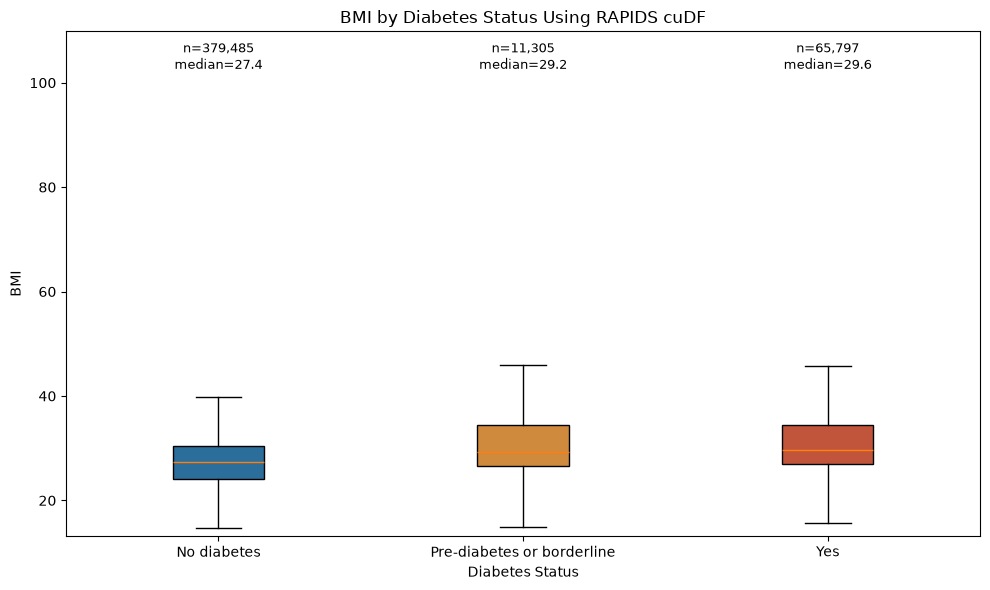

In [34]:
# Create a boxplot of BMI by diabetes status.
# The BMI values are converted to pandas only for Matplotlib.

bmi_plot_data = (
    gdf[["diabetes_status", "bmi"]]
    .to_pandas()
)

bmi_values = [
    bmi_plot_data[
        bmi_plot_data["diabetes_status"] == status
    ]["bmi"]
    .dropna()
    .values
    for status in bmi_status_order
]

plt.figure(figsize=(10, 6))

boxplot_result = plt.boxplot(
    bmi_values,
    patch_artist=True,
    showfliers=False
)

box_colors = [
    "#2C6E9B",
    "#D08A3E",
    "#C1553B"
]

for box, color in zip(
    boxplot_result["boxes"],
    box_colors
):
    box.set_facecolor(color)

plt.xticks(
    [1, 2, 3],
    bmi_status_order
)

plt.xlabel("Diabetes Status")
plt.ylabel("BMI")
plt.title(
    "BMI by Diabetes Status Using RAPIDS cuDF",
    fontsize=12
)

# Display sample size and median above each box
bmi_maximum = bmi_plot_data["bmi"].max()

for position, status in enumerate(
    bmi_status_order,
    start=1
):
    status_values = bmi_plot_data[
        bmi_plot_data["diabetes_status"] == status
    ]["bmi"].dropna()
    
    plt.text(
        position,
        bmi_maximum + 2,
        f"n={len(status_values):,}\n"
        f"median={status_values.median():.1f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylim(None, bmi_maximum + 10)
plt.tight_layout()
plt.show()

Conclusion: The median BMI increases from the No diabetes group to the Pre-diabetes or borderline group and is highest for the Yes group. This creates a clear dose-response pattern between BMI and diabetes status.

BMI appears to be one of the strongest numeric candidate features for the prediction model. The boxplot also shows variation within every group, so BMI should not be used as the only predictor.

RAPIDS EDA 9 · BMI and age relationship

Question: Are age and BMI redundant with each other, and how do they appear across diabetes-status groups?

A scatterplot is created using an 8,000-row sample for readability. Pearson and Spearman correlations are calculated using the full dataset.

In [35]:
# Calculate Pearson and Spearman correlations between age and BMI.
# The correlations use the full dataset.

correlation_columns = [
    "age",
    "bmi"
]


# Calculate correlations using pandas
start_time = time.perf_counter()

pandas_pearson_matrix = (
    pdf[correlation_columns]
    .corr(method="pearson")
)

pandas_spearman_matrix = (
    pdf[correlation_columns]
    .corr(method="spearman")
)

pandas_pearson = pandas_pearson_matrix.loc["age", "bmi"]
pandas_spearman = pandas_spearman_matrix.loc["age", "bmi"]

pandas_correlation_time = time.perf_counter() - start_time


# Calculate correlations using cuDF
start_time = time.perf_counter()

cudf_pearson_matrix = (
    gdf[correlation_columns]
    .corr(method="pearson")
)

cudf_spearman_matrix = (
    gdf[correlation_columns]
    .corr(method="spearman")
)

# Convert the small correlation matrices to pandas
cudf_pearson_matrix_pd = (
    cudf_pearson_matrix
    .to_pandas()
)

cudf_spearman_matrix_pd = (
    cudf_spearman_matrix
    .to_pandas()
)

cudf_pearson = cudf_pearson_matrix_pd.loc["age", "bmi"]
cudf_spearman = cudf_spearman_matrix_pd.loc["age", "bmi"]

rapids_correlation_time = time.perf_counter() - start_time


correlation_comparison = pd.DataFrame({
    "Correlation_Type": [
        "Pearson",
        "Spearman"
    ],
    "Pandas": [
        pandas_pearson,
        pandas_spearman
    ],
    "cuDF": [
        cudf_pearson,
        cudf_spearman
    ]
}).round(4)

print("Age and BMI correlation comparison:")
display(correlation_comparison)


# Compare execution times
correlation_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_correlation_time,
        rapids_correlation_time
    ]
})

correlation_timing["Speedup_Ratio"] = (
    pandas_correlation_time /
    correlation_timing["Execution_Time_Seconds"]
).round(2)

print("Correlation execution-time comparison:")
display(correlation_timing)

Age and BMI correlation comparison:


,Correlation_Type,Pandas,cuDF
0,Pearson,-0.0134,-0.0134
1,Spearman,-0.0127,-0.0127


Correlation execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.172365,1.00
1,cuDF,2.129838,0.08


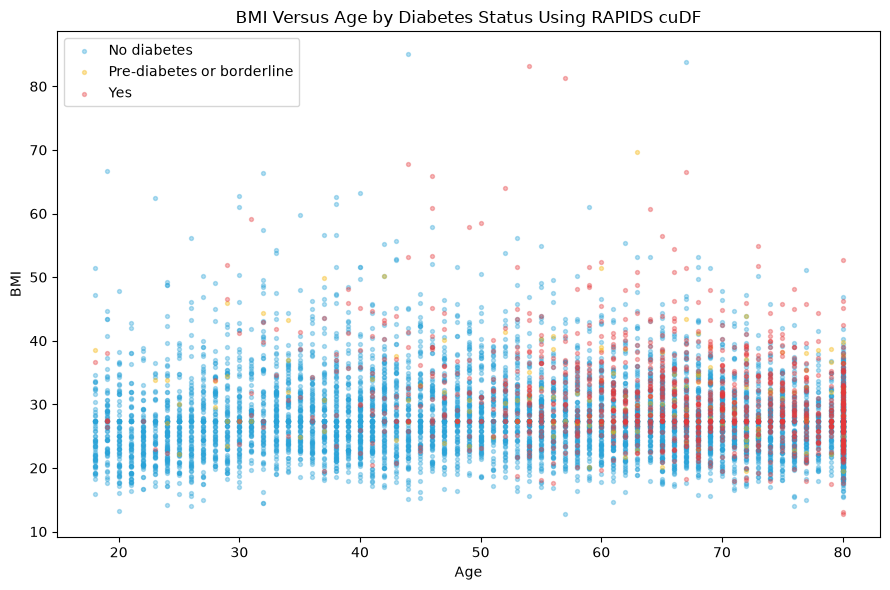

In [36]:
# Create a scatterplot using an 8,000-row sample.
# The sample makes the graph easier to read while correlations use all rows.

scatter_sample = (
    gdf[
        ["age", "bmi", "diabetes_status"]
    ]
    .sample(n=8000, random_state=7)
    .to_pandas()
)

plot_colors = {
    "No diabetes": "#29A3D8",
    "Pre-diabetes or borderline": "#F5B301",
    "Yes": "#E5383B"
}

plt.figure(figsize=(9, 6))

for diabetes_status in [
    "No diabetes",
    "Pre-diabetes or borderline",
    "Yes"
]:
    status_data = scatter_sample[
        scatter_sample["diabetes_status"]
        == diabetes_status
    ]
    
    plt.scatter(
        status_data["age"],
        status_data["bmi"],
        s=8,
        alpha=0.35,
        color=plot_colors[diabetes_status],
        label=diabetes_status
    )

plt.xlabel("Age")
plt.ylabel("BMI")
plt.title(
    "BMI Versus Age by Diabetes Status Using RAPIDS cuDF",
    fontsize=12
)

plt.legend()
plt.tight_layout()
plt.show()

Conclusion: The Pearson and Spearman correlation values are both close to zero, showing that age and BMI are not strongly redundant with each other. The scatterplot also shows that the diabetes-status groups overlap, although the BMI distribution appears higher for diabetes and pre-diabetes respondents.

Age and BMI should both be retained as model features because they provide different information. The correlation result only evaluates redundancy between age and BMI; it does not measure their complete relationship with diabetes status.

RAPIDS EDA 10 · Smoking status and diabetes association

Question: Is the relationship between smoking status and diabetes stronger than what could occur by chance?

A contingency table is created using pandas and cuDF. A chi-square test and Cramér's V are then used to measure statistical significance and practical association strength.

In [41]:
# Test whether smoking status and diabetes status are associated.
# cuDF creates the contingency table, while SciPy performs the
# chi-square calculation on the small summary table.

from scipy.stats import chi2_contingency


# Create the contingency table using pandas
start_time = time.perf_counter()

pandas_contingency = pd.crosstab(
    pdf["smoking_status"],
    pdf["diabetes_status"]
)

pandas_contingency = (
    pandas_contingency
    .reindex(
        index=smoking_order,
        columns=diabetes_status_order,
        fill_value=0
    )
)

pandas_chi2, pandas_p_value, pandas_dof, _ = (
    chi2_contingency(pandas_contingency)
)

pandas_sample_size = pandas_contingency.values.sum()

pandas_cramers_v = (
    pandas_chi2 /
    (pandas_sample_size *
     (min(pandas_contingency.shape) - 1))
) ** 0.5

pandas_chi_square_time = time.perf_counter() - start_time


# Create the contingency table using cuDF
start_time = time.perf_counter()

cudf_contingency = cudf.crosstab(
    gdf["smoking_status"],
    gdf["diabetes_status"]
)

# Convert only the small contingency table to pandas
cudf_contingency_pd = (
    cudf_contingency
    .to_pandas()
    .reindex(
        index=smoking_order,
        columns=diabetes_status_order,
        fill_value=0
    )
)

cudf_chi2, cudf_p_value, cudf_dof, _ = (
    chi2_contingency(cudf_contingency_pd)
)

cudf_sample_size = cudf_contingency_pd.values.sum()

cudf_cramers_v = (
    cudf_chi2 /
    (cudf_sample_size *
     (min(cudf_contingency_pd.shape) - 1))
) ** 0.5

rapids_chi_square_time = time.perf_counter() - start_time


print("Contingency table using pandas:")
display(pandas_contingency)

print("Contingency table using cuDF:")
display(cudf_contingency_pd)


print("Pandas chi-square:", round(pandas_chi2, 2))
print("Pandas degrees of freedom:", pandas_dof)
print("Pandas p-value:", pandas_p_value)
print("Pandas Cramer's V:", round(pandas_cramers_v, 3))

print("\ncuDF chi-square:", round(cudf_chi2, 2))
print("cuDF degrees of freedom:", cudf_dof)
print("cuDF p-value:", cudf_p_value)
print("cuDF Cramer's V:", round(cudf_cramers_v, 3))


# Compare execution times
chi_square_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_chi_square_time,
        rapids_chi_square_time
    ]
})

chi_square_timing["Speedup_Ratio"] = (
    pandas_chi_square_time /
    chi_square_timing["Execution_Time_Seconds"]
).round(2)

print("\nChi-square execution-time comparison:")
display(chi_square_timing)

Contingency table using pandas:


diabetes_status,No diabetes,Yes,Pre-diabetes or borderline
smoking_status,,,
Current smoker - every day,26725,5282,1012
Current smoker - some days,11741,1804,380
Former smoker,94570,21515,3300
Never smoker,219722,32772,5960


Contingency table using cuDF:


diabetes_status,No diabetes,Yes,Pre-diabetes or borderline
smoking_status,,,
Current smoker - every day,26725,5282,1012
Current smoker - some days,11741,1804,380
Former smoker,94570,21515,3300
Never smoker,219722,32772,5960


Pandas chi-square: 2159.46
Pandas degrees of freedom: 6
Pandas p-value: 0.0
Pandas Cramer's V: 0.05

cuDF chi-square: 2159.46
cuDF degrees of freedom: 6
cuDF p-value: 0.0
cuDF Cramer's V: 0.05

Chi-square execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.135698,1.00
1,cuDF,0.083033,1.63


Conclusion: The p-value is expected to be very small because the dataset contains many respondents, indicating that smoking status and diabetes status are statistically associated. However, the Cramér's V value is small, showing that the practical strength of the association is weak.

Smoking status can remain in the dataset as a possible model feature, but it should not be treated as one of the strongest predictors. A higher percentage among former smokers may also reflect people quitting after receiving health concerns or a diagnosis, so the relationship should not be interpreted as causal.

RAPIDS EDA 11 · Numeric predictor correlations

Question: Which numeric predictors are related to each other, and are any variables redundant?

Spearman correlation is used because several numeric variables are skewed. Strong correlations may indicate redundant predictors, while weak correlations suggest that the variables provide different information.

In [42]:
# Calculate the Spearman correlation matrix for numeric predictors.
# This repeats the same analysis using pandas and RAPIDS cuDF.

numeric_columns = [
    "weight_pounds",
    "bmi",
    "alcohol_days_per_month",
    "alcohol_drinks_per_week",
    "age",
    "poor_health_days",
    "cigarettes_per_day",
    "pack_years",
    "binge_drinking_occasions"
]


# Calculate the correlation matrix using pandas
start_time = time.perf_counter()

pandas_spearman_matrix = (
    pdf[numeric_columns]
    .corr(method="spearman")
)

pandas_correlation_time = time.perf_counter() - start_time


# Calculate the same correlation matrix using cuDF
start_time = time.perf_counter()

cudf_spearman_matrix = (
    gdf[numeric_columns]
    .corr(method="spearman")
)

# Convert the small correlation matrix to pandas
cudf_spearman_matrix_pd = (
    cudf_spearman_matrix
    .to_pandas()
)

rapids_correlation_time = time.perf_counter() - start_time


# Compare the two correlation matrices
maximum_difference = (
    pandas_spearman_matrix -
    cudf_spearman_matrix_pd
).abs().to_numpy().max()

print("Maximum difference between pandas and cuDF:",
      round(maximum_difference, 6))

print("\nSpearman correlation matrix using cuDF:")
display(cudf_spearman_matrix_pd.round(2))


# Compare execution times
spearman_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_correlation_time,
        rapids_correlation_time
    ]
})

spearman_timing["Speedup_Ratio"] = (
    pandas_correlation_time /
    spearman_timing["Execution_Time_Seconds"]
).round(2)

print("Spearman-correlation execution-time comparison:")
display(spearman_timing)

Maximum difference between pandas and cuDF: 0.0

Spearman correlation matrix using cuDF:


,weight_pounds,bmi,alcohol_days_per_month,alcohol_drinks_per_week,age,poor_health_days,cigarettes_per_day,pack_years,binge_drinking_occasions
weight_pounds,1.00,0.83,0.02,0.03,-0.06,0.03,0.06,0.05,0.05
bmi,0.83,1.00,-0.07,-0.06,-0.01,0.06,0.04,0.03,-0.00
alcohol_days_per_month,0.02,-0.07,1.00,0.99,-0.07,-0.04,0.03,0.03,0.45
alcohol_drinks_per_week,0.03,-0.06,0.99,1.00,-0.11,-0.04,0.04,0.03,0.51
age,-0.06,-0.01,-0.07,-0.11,1.00,-0.09,0.16,0.17,-0.20
poor_health_days,0.03,0.06,-0.04,-0.04,-0.09,1.00,0.08,0.08,0.03
cigarettes_per_day,0.06,0.04,0.03,0.04,0.16,0.08,1.00,0.95,0.09
pack_years,0.05,0.03,0.03,0.03,0.17,0.08,0.95,1.00,0.09
binge_drinking_occasions,0.05,-0.00,0.45,0.51,-0.20,0.03,0.09,0.09,1.00


Spearman-correlation execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,1.069689,1.00
1,cuDF,0.520354,2.06


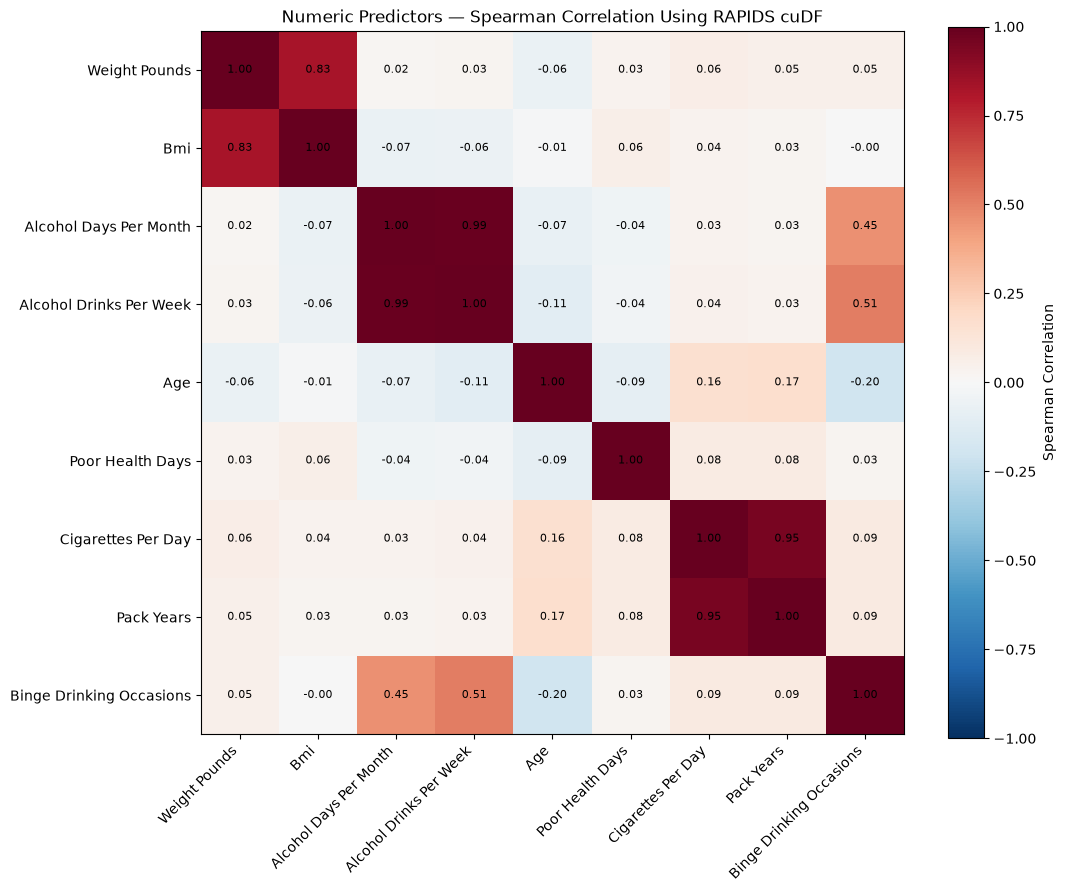

In [43]:
# Plot the cuDF Spearman correlation matrix.
# Matplotlib is used to visualize the small correlation result.

correlation_values = (
    cudf_spearman_matrix_pd
    .loc[numeric_columns, numeric_columns]
    .values
)

short_labels = [
    column.replace("_", " ").title()
    for column in numeric_columns
]

fig, ax = plt.subplots(
    figsize=(11, 9)
)

heatmap = ax.imshow(
    correlation_values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))

ax.set_xticklabels(
    short_labels,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(short_labels)

for row in range(len(numeric_columns)):
    for column in range(len(numeric_columns)):
        ax.text(
            column,
            row,
            f"{correlation_values[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(
    heatmap,
    ax=ax,
    label="Spearman Correlation"
)

ax.set_title(
    "Numeric Predictors — Spearman Correlation Using RAPIDS cuDF",
    fontsize=12
)

plt.tight_layout()
plt.show()

Conclusion: The pandas and cuDF correlation matrices are nearly identical. The heatmap shows stronger relationships among related lifestyle variables, such as cigarettes per day and pack-years. Age and BMI have a relatively weak relationship, meaning they provide different information.

Highly related variables should be reviewed before modelling. BMI and age can both be retained, while closely related smoking or alcohol variables may need regularization or feature selection in a linear model.

RAPIDS EDA 12 · Age and income interaction

Question: Does diabetes prevalence change across age groups and income levels?

This heatmap examines age and income together. Each cell represents the percentage of respondents with diabetes for one age-and-income combination.

In [44]:
# Calculate diabetes prevalence for each age-group and income combination.
# cuDF performs the groupby mean calculation.

age_order = [
    "18-24",
    "25-29",
    "30-34",
    "35-39",
    "40-44",
    "45-49",
    "50-54",
    "55-59",
    "60-64",
    "65-69",
    "70-74",
    "75-79",
    "80+"
]

income_order = [
    "Less than $10,000",
    "$10,000 to less than $15,000",
    "$15,000 to less than $20,000",
    "$20,000 to less than $25,000",
    "$25,000 to less than $35,000",
    "$35,000 to less than $50,000",
    "$50,000 to less than $75,000",
    "$75,000 to less than $100,000",
    "$100,000 to less than $150,000",
    "$150,000 to less than $200,000",
    "$200,000 or more",
    "Unknown"
]


# Calculate age-income prevalence using pandas
start_time = time.perf_counter()

pandas_age_income_long = (
    pdf
    .groupby(
        ["age_group", "detailed_income_level"]
    )["diabetes_yes"]
    .mean()
    .reset_index(name="Diabetes_Rate")
)

pandas_age_income_matrix = (
    pandas_age_income_long
    .pivot(
        index="age_group",
        columns="detailed_income_level",
        values="Diabetes_Rate"
    )
    .reindex(
        index=age_order,
        columns=income_order
    )
    * 100
)

pandas_age_income_time = time.perf_counter() - start_time


# Calculate age-income prevalence using cuDF
start_time = time.perf_counter()

cudf_age_income_long = (
    gdf
    .groupby(
        ["age_group", "detailed_income_level"]
    )["diabetes_yes"]
    .mean()
    .reset_index(name="Diabetes_Rate")
)

# Convert only the small grouped result to pandas for reshaping
cudf_age_income_long_pd = (
    cudf_age_income_long
    .to_pandas()
)

cudf_age_income_matrix = (
    cudf_age_income_long_pd
    .pivot(
        index="age_group",
        columns="detailed_income_level",
        values="Diabetes_Rate"
    )
    .reindex(
        index=age_order,
        columns=income_order
    )
    * 100
)

rapids_age_income_time = time.perf_counter() - start_time


# Compare pandas and cuDF results
maximum_difference = np.nanmax(
    np.abs(
        pandas_age_income_matrix.values -
        cudf_age_income_matrix.values
    )
)

print(
    "Maximum difference between pandas and cuDF:",
    round(maximum_difference, 6),
    "percentage points"
)

print("Age-income diabetes prevalence using cuDF:")
display(cudf_age_income_matrix.round(1))


# Compare execution times
age_income_timing = pd.DataFrame({
    "Method": ["Pandas", "cuDF"],
    "Execution_Time_Seconds": [
        pandas_age_income_time,
        rapids_age_income_time
    ]
})

age_income_timing["Speedup_Ratio"] = (
    pandas_age_income_time /
    age_income_timing["Execution_Time_Seconds"]
).round(2)

print("Age-income execution-time comparison:")
display(age_income_timing)

Maximum difference between pandas and cuDF: 0.0 percentage points
Age-income diabetes prevalence using cuDF:


detailed_income_level,"Less than $10,000","$10,000 to less than $15,000","$15,000 to less than $20,000","$20,000 to less than $25,000","$25,000 to less than $35,000","$35,000 to less than $50,000","$50,000 to less than $75,000","$75,000 to less than $100,000","$100,000 to less than $150,000","$150,000 to less than $200,000","$200,000 or more",Unknown
age_group,,,,,,,,,,,,
18-24,2.2,1.8,2.1,1.4,1.3,1.4,1.3,1.1,0.8,0.7,1.5,1.6
25-29,2.7,3.0,3.2,3.6,1.7,2.1,1.9,1.2,1.6,0.9,1.9,2.1
30-34,5.3,6.3,5.0,4.4,3.6,3.2,2.7,1.7,1.9,1.9,1.5,3.6
35-39,7.8,7.9,6.6,8.5,7.1,5.3,4.2,3.7,3.2,2.3,1.9,4.4
40-44,13.9,14.3,12.7,12.8,9.9,10.0,7.1,5.8,5.3,4.0,2.7,7.0
45-49,19.3,21.6,20.4,17.6,15.4,13.6,12.8,9.0,8.4,6.2,4.4,11.0
50-54,23.6,30.2,29.3,24.4,20.7,18.5,15.2,13.7,12.0,10.0,7.0,14.6
55-59,26.7,30.6,29.6,30.8,24.7,22.0,17.3,16.0,13.2,10.9,8.0,17.6
60-64,30.1,29.9,29.9,29.1,26.2,22.3,18.7,16.6,15.5,12.7,10.8,18.8


Age-income execution-time comparison:


,Method,Execution_Time_Seconds,Speedup_Ratio
0,Pandas,0.329888,1.00
1,cuDF,0.093288,3.54


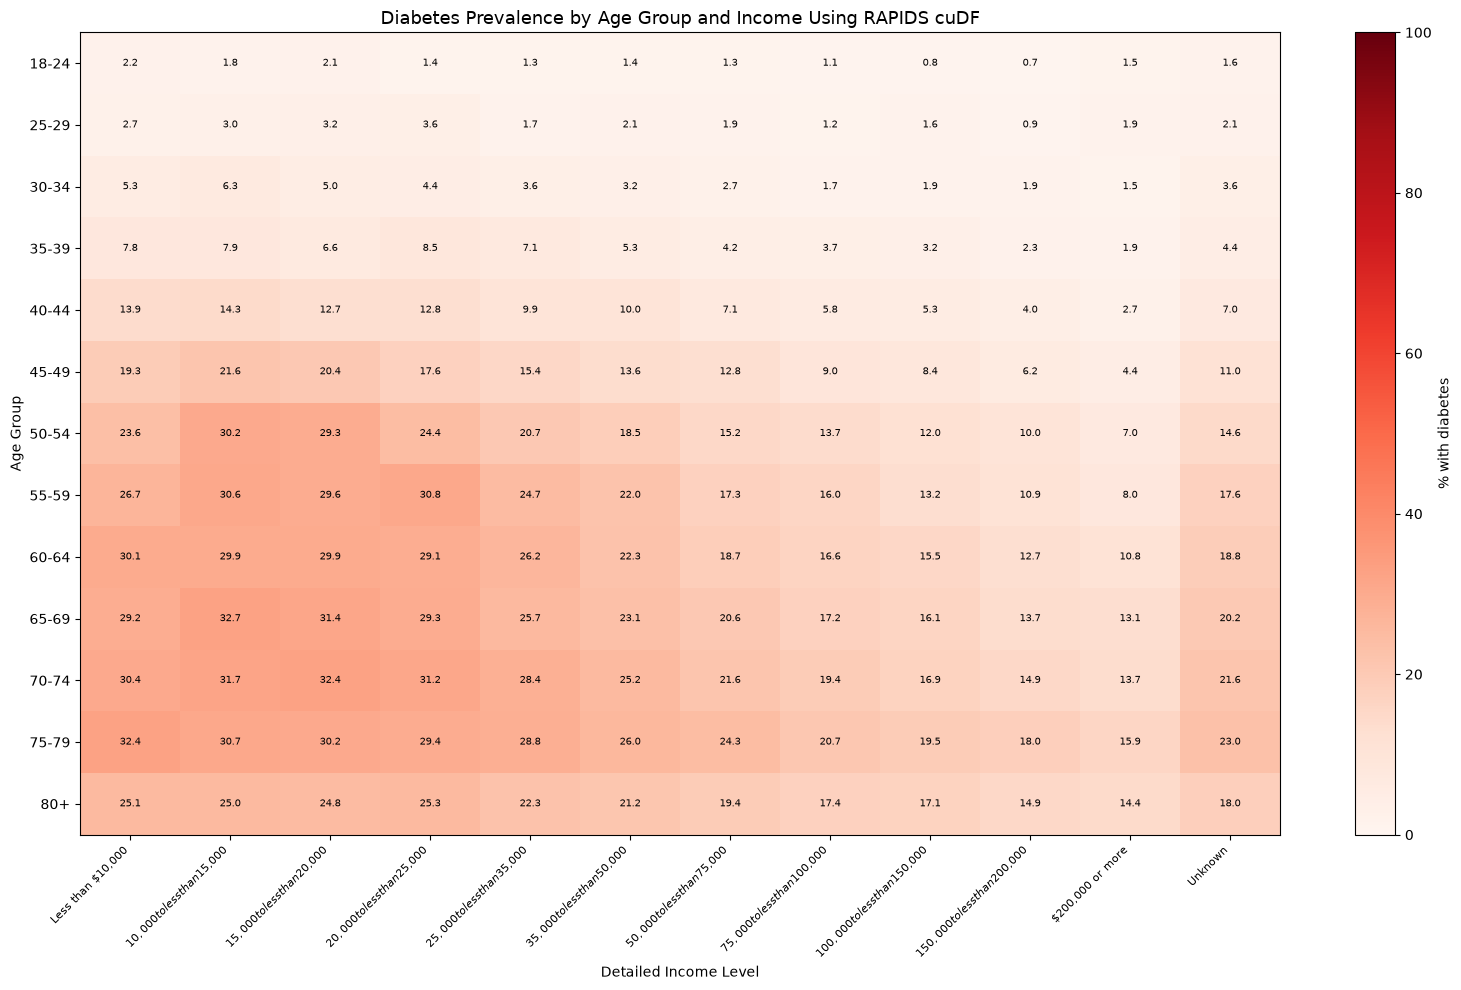

In [45]:
# Plot the cuDF age-income prevalence matrix.
# Matplotlib is used to display the small summary table.

heatmap_values = (
    cudf_age_income_matrix
    .values
)

fig, ax = plt.subplots(
    figsize=(16, 10)
)

heatmap = ax.imshow(
    heatmap_values,
    cmap="Reds",
    vmin=0,
    vmax=100,
    aspect="auto"
)

ax.set_xticks(range(len(income_order)))
ax.set_yticks(range(len(age_order)))

ax.set_xticklabels(
    income_order,
    rotation=45,
    ha="right",
    fontsize=8
)

ax.set_yticklabels(age_order)

for row in range(len(age_order)):
    for column in range(len(income_order)):
        value = heatmap_values[row, column]
        
        if not np.isnan(value):
            ax.text(
                column,
                row,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=7
            )

plt.colorbar(
    heatmap,
    ax=ax,
    label="% with diabetes"
)

ax.set_title(
    "Diabetes Prevalence by Age Group and Income Using RAPIDS cuDF",
    fontsize=13
)

ax.set_xlabel("Detailed Income Level")
ax.set_ylabel("Age Group")

plt.tight_layout()
plt.show()

Conclusion: Diabetes prevalence generally increases across older age groups and tends to decrease as income increases. The heatmap shows that age and income provide useful information together rather than separately.

Age group and income level should be retained as model features. Their interaction may also be useful because income differences appear within several age groups.

RAPIDS EDA 13 · Final cleanup and timing comparison

Question: Did RAPIDS produce the same EDA results as pandas, and how did the execution times compare?

The temporary EDA column is removed before the final shape is checked. Execution times from the repeated analyses are combined into one summary table.

In [46]:
# Remove the temporary diabetes_yes column.
# This column was used only for EDA prevalence calculations.

if "diabetes_yes" in pdf.columns:
    pdf = pdf.drop(columns=["diabetes_yes"])

if "diabetes_yes" in gdf.columns:
    gdf = gdf.drop(columns=["diabetes_yes"])


print("Temporary EDA column removed.")
print("Final pandas shape:", pdf.shape)
print("Final cuDF shape:", gdf.shape)

print(
    "Remaining missing values in cuDF:",
    int(gdf.isna().sum().sum())
)

Temporary EDA column removed.
Final pandas shape: (456587, 30)
Final cuDF shape: (456587, 30)
Remaining missing values in cuDF: 0


In [52]:
# Combine the execution times from the main EDA operations.

timing_summary = pd.DataFrame({
    "EDA_Task": [
        "File loading",
        "Target distribution",
        "Numeric summary and skew",
        "Lifestyle prevalence",
        "Demographic prevalence",
        "Age and gender counts",
        "Health and activity analysis",
        "Smoking analysis",
        "BMI by diabetes status",
        "Spearman correlation matrix",
        "Smoking crosstab + SciPy chi-square",
        "Age-income prevalence (cuDF groupby + pandas pivot)"
    ],
    "Pandas_Time_Seconds": [
        pandas_load_time,
        pandas_target_time,
        pandas_numeric_time,
        pandas_lifestyle_time,
        pandas_demographic_time,
        pandas_age_gender_time,
        pandas_health_time,
        pandas_smoking_time,
        pandas_bmi_time,
        pandas_correlation_time,
        pandas_chi_square_time,
        pandas_age_income_time
    ],
    "cuDF_Time_Seconds": [
        rapids_load_time,
        rapids_target_time,
        rapids_numeric_time,
        rapids_lifestyle_time,
        rapids_demographic_time,
        rapids_age_gender_time,
        rapids_health_time,
        rapids_smoking_time,
        rapids_bmi_time,
        rapids_correlation_time,
        rapids_chi_square_time,
        rapids_age_income_time
    ]
})

timing_summary["Time_Difference_Seconds"] = (
    timing_summary["Pandas_Time_Seconds"] -
    timing_summary["cuDF_Time_Seconds"]
).round(4)

timing_summary["cuDF_Speedup_Ratio"] = (
    timing_summary["Pandas_Time_Seconds"] /
    timing_summary["cuDF_Time_Seconds"]
).round(2)

print("Final pandas versus cuDF timing summary:")
display(timing_summary.round(4))

Final pandas versus cuDF timing summary:


,EDA_Task,Pandas_Time_Seconds,cuDF_Time_Seconds,Time_Difference_Seconds,cuDF_Speedup_Ratio
0,File loading,3.4654,1.7508,1.7147,1.98
1,Target distribution,0.2940,0.7312,-0.4372,0.40
2,Numeric summary and skew,0.6289,1.4268,-0.7979,0.44
3,Lifestyle prevalence,0.6168,0.3849,0.2320,1.60
4,Demographic prevalence,0.4500,0.2147,0.2353,2.10
5,Age and gender counts,0.0154,0.0249,-0.0095,0.62
6,Health and activity analysis,0.1649,0.9351,-0.7703,0.18
7,Smoking analysis,0.0523,0.0465,0.0058,1.12
8,BMI by diabetes status,0.1154,0.7056,-0.5902,0.16
9,Spearman correlation matrix,1.0697,0.5204,0.5493,2.06


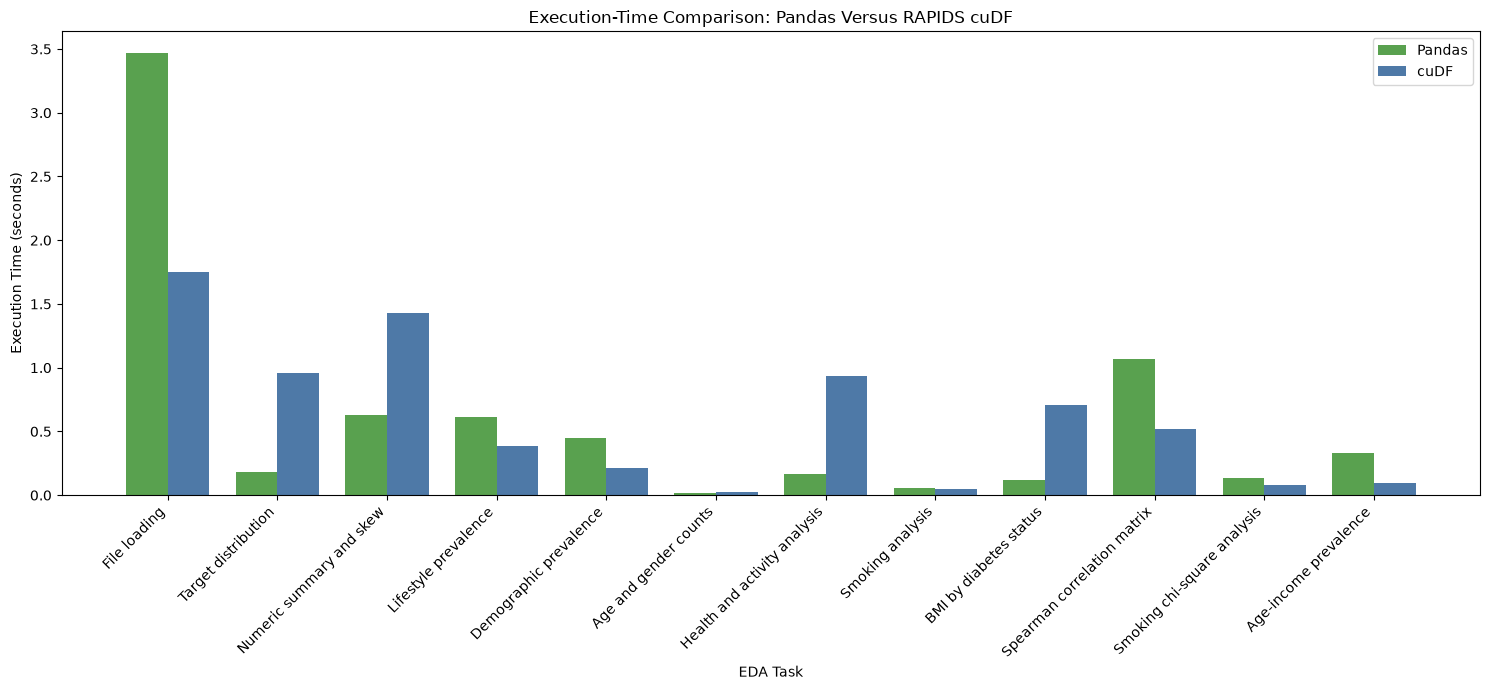

In [48]:
# Plot the execution-time comparison for the main EDA tasks.

x_positions = np.arange(len(timing_summary))
bar_width = 0.38

plt.figure(figsize=(15, 7))

plt.bar(
    x_positions - bar_width / 2,
    timing_summary["Pandas_Time_Seconds"],
    width=bar_width,
    label="Pandas",
    color="#59A14F"
)

plt.bar(
    x_positions + bar_width / 2,
    timing_summary["cuDF_Time_Seconds"],
    width=bar_width,
    label="cuDF",
    color="#4E79A7"
)

plt.xlabel("EDA Task")
plt.ylabel("Execution Time (seconds)")
plt.title("Execution-Time Comparison: Pandas Versus RAPIDS cuDF")

plt.xticks(
    x_positions,
    timing_summary["EDA_Task"],
    rotation=45,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

Conclusion: The pandas and cuDF results were consistent because both methods used the same cleaned dataset and produced equivalent summaries. The timing comparison shows that RAPIDS performance depends on the type and size of the operation.

cuDF is more likely to benefit larger calculations involving grouping, correlation, and aggregation. For smaller calculations, pandas may be similar or faster because GPU processing has startup and data-transfer overhead. The graph and timing table report the actual performance observed on this computer.